# GROWL task force — individual data projects
# Step 1: Download and investigate your dataset

**Welcome to your own GROWL data project!** 🦖 🦕

Up to now (the [onboarding notebooks](../../../onboarding_growl/)) everyone worked on the *same*
example data. From here on **you get your own published dataset** — a population synthesis
simulation from a paper — and your job over the next weeks is to bring it into the
**GROWL catalog** so that the whole task force can use it.

This notebook is the **instruction sheet for step 1**. It tells you what to do, and it contains
**empty tables and code templates for you to fill in**. You are meant to make a copy of this notebook -> move it to your specific project working folder and edit your personal copy there. We will use the information that you obtain for your simulation for the GROWL catalog. Let us know when you are done and we can give you more data. We hope to have the first version of the GROWL catalog done & written up by ~NOV/DEC 2026 after which we will move to fun individual astrophysics projects (applying GROWL catalog data to different astrophysics problems) as well as building version 2 of the catalog. This is very much a work in progress. We are also building shared code to help with all of this and to make your part. Please dont hesitate to reach out. 


> 🧭 **How to use this notebook**
> 1. Copy this notebook into **your own project folder** under
>    `GROWL_TF_individual_data_projects/individual_project_folders/` and rename it
>    `step1_<dataset>_<yourname>.ipynb` (see [§0.3](#where)).
> 2. Work through **Tasks A → G** below. Fill in every table and every code template.
> 3. Bring your filled-in notebook to the next task force meeting: dont wait until you have done all tasks, we would love to see intermediate results (that is: what you get for each step!). These are all going to be new results/things we have never looked into; so it will be super interesting to see what you find! 
>
> ✋ **Nothing here is a test.** If something is unclear, missing from the paper, or simply not in
> the data — **write "unknown" or "not in file" and ask**. Discovering that a published dataset
> does *not* contain something is a genuine and useful result. Half of this work is finding out
> what is missing.

---

<a id="roadmap"></a>
## 0.1 The road map

| Step | Notebook | What you do | Status |
|---|---|---|---|
| **1** | `step1_download_and_investigate_data` | Find the paper and the data, download it, record the paths, open the file, and document **exactly what is inside**. | 👈 **you are here** |
| 2 | `step2_...` | *(to be released)* | |
| 3 | `step3_...` | *(to be released)* | |
| 4 | `step4_...` | *(to be released)* | |

### The tasks in this step

| Task | What | Deliverable |
|---|---|---|
| **[A](#taskA)** | Where does this dataset come from? | Filled-in provenance table + submodel table |
| **[B](#taskB)** | Write the paths down as a **dictionary** | A code cell others can copy and run |
| **[C](#taskC)** | Download the data, and log **exactly** how you did it | A step-by-step recipe + list of difficulties |
| **[D](#taskD)** | Read the paper and summarise it | Goal, DCO types, authors, figure-by-figure list |
| **[E](#taskE)** | Read the methods section → fill the **metadata table** | Filled + fact-checked metadata rows |
| **[F](#taskF)** | Open the file and compare it with the tutorial file | Group/column listing, sanity plot, comparison table |
| **[G](#taskG)** | Write the summary card | The card that goes into the GROWL catalog |

<a id="why"></a>
## 0.2 Why this step of investigating the data matters

It is tempting to skip straight to making plots. **Don't.** Almost every mistake made with someone
else's simulation output is made in the first hour:

- You assume a column means one thing and it means another (`Mass(1)` is *not* always the heavier
  object; `Time` may be formation time or delay time).
- You count rows in a catalogue that was **importance sampled / used weights**, so every number you quote is wrong
  by a factor of a few (onboarding Notebook 2, §1.4 — ⚖️ *never count rows, always sum weights*).
- You use a file that turns out to be a **model variation**, not the fiducial model of the paper,
  and then wonder why your plot does not match the paper's figure.
- You assume two files from the same authors contain the same groups and columns. They very often
  do not.
- Six months later nobody — including you — remembers where the file came from or how to get it
  again. **That is what Tasks A, B and C are for.**

<a id="where"></a>
## 0.3 Where to put your work

```
GROWL-catalog-public/
└── GROWL_TF_individual_data_projects/
    ├── instructions_task_force/                      <- these instruction notebooks
    │   └── step1_download_and_investigate_data.ipynb    (read them; don't edit them)
    └── individual_project_folders/                   <- everybody's working folders
        ├── vanSon22noPeaks_1__Maryam_Ahsan/          <- one folder per student + dataset
        │   ├── vanSon22noPeaks_beta0_5_zetaHG4_5_RMS_Delayed.ipynb
        │   └── step1_vanSon22noPeaks_<yourname>.ipynb   <- your copy of THIS notebook
        └── <dataset>_<n>__<yourname>/                <- YOUR folder
            └── step1_<dataset>_<yourname>.ipynb
```

**The folder name** follows the pattern `<dataset>_<n>__<yourname>`:

| Piece | What it is | Example |
|---|---|---|
| `<dataset>` | the same `name_folder` you choose in [Task B](#taskB) — first author + year + short tag | `vanSon22noPeaks` |
| `<n>` | which project this is, if one dataset is split over several people | `1` |
| `<yourname>` | you, after a **double** underscore | `__Maryam_Ahsan` |

So the example folder that already exists is
`individual_project_folders/vanSon22noPeaks_1__Maryam_Ahsan/`.

**Work inside your own folder only.** Copy this notebook there, rename it
`step1_<dataset>_<yourname>.ipynb`, and edit *that* copy — never this original. Any other notebook
you are given for your dataset goes in the same folder.

> 🔗 **One thing to fix after you copy.** Your folder sits one level deeper than this one, so the
> links in this notebook that start with `../../` (to the onboarding notebooks) need **one more**
> `../` from there: `../../../../onboarding_growl/...`. If a link does not work, that is why.

> ⚠️ **Never commit the data itself to git.** The HDF5 files are gigabytes; the repository holds
> *notebooks and code only*. The data lives on the **GROWL drive** (`/Volumes/GROWL/GROWL_bps/...`)
> and/or on your own machine, and your notebook points at it through the dictionary of Task B.

---

<a id="taskA"></a>
# Task A — Where does this dataset come from?

**A.1** — Read (at least skim) the paper your dataset belongs to. You need to be able to answer, in
one or two sentences each:

- What question is the paper asking? \
*The paper asks what astrophysical processes impact the SMT channel for formation of low mass DCOs.*

- Which simulation code was used, and which **version**? \
*COMPAS simulation, version **v02.26.03** was used.*

- What is the paper's **fiducial** (= default, reference) model? \
*The fiducial model is **faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2012SNDELAYED**, which is available in dataset 2.*

- Which physics assumptions were **varied**, and what are those variations called? \
*The study varied the following physical assumptions governing stellar and binary evolution: **mass transfer efficiency, angular momentum loss, mass transfer stability, stellar core masses, and supernova remnant formation**. In the dataset, these are controlled by nine named settings.Some variations change the prescription—the rule used to model the physics—while others change a parameter within that prescription. These variations are labelled facc, beta, gamma, fcircum, zetaHG, fcore, RemMass, SN, and fmix in the dataset filenames.*



**A.2** — Find the data. In order of preference:

1. A **Zenodo** record (`https://zenodo.org/records/...`) — usually linked in the paper's
   *Data Availability* section or a footnote.
2. Another archive: [GWLandscape](https://gwlandscape.org.au/), Harvard Dataverse, Figshare, a
   Google Drive link in the paper, the authors' GitHub repository.
3. The **GROWL drive** — the data may already be there: `/Volumes/GROWL/GROWL_bps/`.
4. If none of these work: **ask Floor**, who can email the authors.

> 📌 A **DOI** (digital object identifier, e.g. `10.5281/zenodo.7080725`) is the permanent address
> of a dataset. Always record the DOI, not only the web link — links rot, DOIs do not. Many Zenodo
> records have a "concept DOI" (all versions) *and* a per-version DOI: record the one you actually
> downloaded.

**A.3** — ⚠️ **Check that the archive cites the paper you think it does.** Data pages contain
typos surprisingly often. Compare the *title* on the archive page with the title of your paper, not
just the arXiv number. /

***Note:** The zenodo records state the name of the paper correctly, but sites a different paper by the same author.*

## 📚 Fill in: Where this dataset comes from

👉 **Double-click this cell to edit it** and fill in every row. Delete rows that do not apply, add
rows if you have more sources. (Never written a markdown table? The `|` characters separate the
columns and the `|---|---|` line marks the header — just type between the bars.)

| | |
|---|---|
| 📄 **Paper** — van Son, de Mink, Renzo, Justham, Zapartas, Breivik, Callister, Farr & Conroy (2022), *No peaks without valleys: The stable mass transfer channel for gravitational-wave sources in light of the neutron star–black hole mass gap*, ApJ **940**, 184 | 👉 https://doi.org/10.3847/1538-4357/ac9b0a <br> 👉 https://arxiv.org/abs/2209.13609 |
| 💾 **Data, part 1 of 2 (Zenodo)** — DOI `10.5281/zenodo.7080725` — 13 model variations, one `.tar.gz` each | 👉 https://zenodo.org/records/7080725 |
| 💾 **Data, part 2 of 2 (Zenodo)** — DOI `10.5281/zenodo.7080164` — 13 more, including the *fiducial* model `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2012SNDELAYED` | 👉 https://zenodo.org/records/7080164 |
| 🗂️ **Submodels** — 26 simulations of $10^7$ binaries each; one uncertain parameter varied at a time ($\beta_\mathrm{acc}$, $\zeta_\mathrm{eff}$, $f_\mathrm{core}$, $f_\mathrm{circum}$, remnant-mass prescription) | *see table below* |
| 💻 **Analysis code by the authors** | 👉 https://github.com/LiekeVanSon/LowMBH_and_StableChannel |
| 💻 **The simulation code**, COMPAS v02.26.03 ([methods paper](https://arxiv.org/abs/2109.10352)) | 👉 https://compas.science/ |
| 📁 **Local copy** — paper (`vanSon22noPeaks.pdf`) and Zenodo README are in the same folder as the data | `E:/GitHub/Data/vanSon22noPeaks_1/` |
| 👤 **Contact** — L. van Son | *not contacted* |

<details>
<summary>👀 <b>Click here for a worked example</b> (what a filled-in table looks like)</summary>

| | |
|---|---|
| 📄 **Paper** — van Son, de Mink, Renzo, Justham, Zapartas, Breivik, Callister, Farr & Conroy (2022), *No peaks without valleys: The stable mass transfer channel for gravitational-wave sources in light of the neutron star–black hole mass gap*, ApJ **940**, 184 | 👉 https://doi.org/10.3847/1538-4357/ac9b0a <br> 👉 https://arxiv.org/abs/2209.13609 |
| 💾 **Data, part 1 of 2 (Zenodo)** — DOI `10.5281/zenodo.7080725` — 13 model variations, one `.tar.gz` each | 👉 https://zenodo.org/records/7080725 |
| 💾 **Data, part 2 of 2 (Zenodo)** — DOI `10.5281/zenodo.7080164` — 13 more, including the *fiducial* model `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2012SNDELAYED` | 👉 https://zenodo.org/records/7080164 |
| 🗂️ **Submodels** — 26 simulations of $10^7$ binaries each; one uncertain parameter varied at a time ($\beta_\mathrm{acc}$, $\zeta_\mathrm{eff}$, $f_\mathrm{core}$, $f_\mathrm{circum}$, remnant-mass prescription) | *see table below* |
| 💻 **Analysis code by the authors** | 👉 https://github.com/LiekeVanSon/LowMBH_and_StableChannel |
| 💻 **The simulation code**, COMPAS v02.26.03 ([methods paper](https://arxiv.org/abs/2109.10352)) | 👉 https://compas.science/ |
| 📁 **Local copy** — paper (`paper.pdf`) and Zenodo README are in the same folder as the data | `/Volumes/GROWL/GROWL_bps/vanSon22noPeaks/` |
| 👤 **Contact** — L. van Son | *not contacted* |

⚠️ Note the kind of thing worth flagging: both Zenodo records above list "arXiv:2209.03385" as the
related paper, which is a **different** van Son et al. paper. The correct one is arXiv:2209.13609.
Exactly the trap A.3 is about.

</details>

## A.4 — The submodels

Almost every population synthesis paper runs **more than one simulation**: a *fiducial* model plus
a set of **variations** in which one uncertain ingredient is changed at a time (the mass transfer
efficiency, the common-envelope efficiency $\alpha_\mathrm{CE}$, the supernova kick distribution,
the remnant mass prescription, the metallicity range, ...).

> 📖 **Vocabulary.** In GROWL we call each individual simulation within one paper's dataset a
> **submodel**, and the catalog is organised as **dataset → submodel → file**:
> ```
> /Volumes/GROWL/GROWL_bps/<dataset>/<submodel>/<file>.h5
> ```
> Papers use other words for the same thing — "model variation", "run", "realisation",
> "model A/B/C". Whatever the paper calls them, they are your submodels.

- **List every submodel**, even the ones you will not analyse. We want the catalog to record what
  exists.
- **Identify the fiducial model.** If the paper does not say so explicitly, look for the model used
  in most figures, or the one matching the "reference value" column of the paper's parameter table.
  If you cannot tell, write "unclear — ask".
- **Decode the names.** Authors usually encode the varied parameter in the file or folder name
  (`alpha0_1beta0_25`, `zetaHG4.5`, `unstableCaseBB`, `modelB`). Work out what each piece means
  using the paper. This decoding is one of the most valuable things you will produce — it is what
  lets someone else use the data without re-reading the paper.



### 🗂️ Fill in: the submodels in my dataset

In [3]:
# Coding the table to make it scrollable

import markdown
from IPython.display import HTML, display

table_markdown = r"""
### Dataset 1 — Zenodo 7080725

| ⭐ | Submodel name (as in the archive) | Folder name we will use | Short label | What is varied | Fiducial value | Archive file | Size (.tar.gz) | Downloaded? |
|---|---|---|---|---|---|---|---|---|
| | `faccFIXEDbeta0.0zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED` | β<sub>acc</sub> = 0  | Fixed accretion efficiency: no transferred mass retained | β<sub>acc</sub> = 0.5 | `faccFIXEDbeta0.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 3.2 GB | ☑ |
| | `faccFIXEDbeta0.5zetaHG4.5RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED` | ζ<sub>eff</sub> = 4.5 | Donor response: transfer becomes unstable more easily | ζ<sub>eff</sub> = 6.0 | `faccFIXEDbeta0.5zetaHG4.5RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☑ |
| | `faccFIXEDbeta0.5zetaHG5.5RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED` | ζ<sub>eff</sub> = 5.5 | Donor response: transfer becomes unstable more easily | ζ<sub>eff</sub> = 6.0 | `faccFIXEDbeta0.5zetaHG5.5RemMassFRYER2012SNDELAYED.tar.gz` | 2.1 GB | ☑ |
| | `faccFIXEDbeta0.5fcore0.8zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>core</sub> = 0.8 | Core mass multiplier: 0.8 | Multiplier 1.0; fcore ≈ 0.34 | `faccFIXEDbeta0.5fcore0.8zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 1.1 GB | ☑ |
| | `faccFIXEDbeta0.5fcore0.9zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>core</sub> = 0.9 | Core mass multiplier: 0.9 | Multiplier 1.0; fcore ≈ 0.34 | `faccFIXEDbeta0.5fcore0.9zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 1.7 GB | ☑ |
| | `faccFIXEDbeta0.5fcore1.0zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>core</sub> = 1.0 | Core mass multiplier 1.0 | Multiplier 1.0; fcore ≈ 0.34 | `faccFIXEDbeta0.5fcore1.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☑ |
| | `faccFIXEDbeta0.5fcore1.1zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>core</sub> = 1.1 | Core mass multiplier: 1.1 | Multiplier 1.0; fcore ≈ 0.34 | `faccFIXEDbeta0.5fcore1.1zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.8 GB | ☑ |
| | `faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>core</sub> = 1.2 | Core mass multiplier: 1.2 | Multiplier 1.0; fcore ≈ 0.34 | `faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 3.6 GB | ☑ |
| | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.0zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>disk</sub> = 0 | MIXTURE: no escaping mass lost through the circumbinary disk | ISOTROPIC; fcircum = 0 | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☑ |
| | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.25zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>disk</sub> = 0.25 | MIXTURE: 25% of escaping mass lost through the circumbinary disk | ISOTROPIC; fcircum = 0 | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.25zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.9 GB | ☑ |
| | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.5zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5gammaMIXTUREfcircum0_5zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>disk</sub> = 0.5 | MIXTURE: 50% of escaping mass lost through the circumbinary disk | ISOTROPIC; fcircum = 0 | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.5zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.7 GB | ☑ |
| | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.75zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5gammaMIXTUREfcircum0_75zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>disk</sub> = 0.75 | MIXTURE: 75% of escaping mass lost through the circumbinary disk | ISOTROPIC; fcircum = 0 | `faccFIXEDbeta0.5gammaMIXTUREfcircum0.75zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 1.7 GB | ☑ |
| | `faccFIXEDbeta0.5gammaMIXTUREfcircum1.0zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5gammaMIXTUREfcircum1_0zetaHG6_0RemMassFRYER2012SNDELAYED` | f<sub>disk</sub> = 1 | MIXTURE: all escaping mass lost through the circumbinary disk | ISOTROPIC; fcircum = 0 | `faccFIXEDbeta0.5gammaMIXTUREfcircum1.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 1.6 GB | ☑ |

### Dataset 2 — Zenodo 7080164

| ⭐ | Submodel name (as in the archive) | Folder name we will use | Short label | What is varied | Fiducial value | Archive file | Size (.tar.gz) | Downloaded? |
|---|---|---|---|---|---|---|---|---|
| ⭐ | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2012SNDELAYED` | fiducial | — | FIXED; β<sub>acc</sub>= 0.5; ζ<sub>eff</sub> = 6.0; FRYER2012, DELAYED | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☐ |
| | `faccFIXEDbeta0.25zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_25zetaHG6_0RemMassFRYER2012SNDELAYED` | β<sub>acc</sub> = 0.25 | Fixed accretion efficiency: 25% of transferred mass retained | β<sub>acc</sub> = 0.5 | `faccFIXEDbeta0.25zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.8 GB | ☐ |
| | `faccFIXEDbeta0.75zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_75zetaHG6_0RemMassFRYER2012SNDELAYED` | β<sub>acc</sub> = 0.75 | Fixed accretion efficiency: 75% of transferred mass retained | β<sub>acc</sub> = 0.5 | `faccFIXEDbeta0.75zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.1 GB | ☐ |
| | `faccFIXEDbeta1.0zetaHG6.0RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta1_0zetaHG6_0RemMassFRYER2012SNDELAYED` | β<sub>acc</sub> = 1 | Fixed accretion efficiency: fully conservative transfer onto the stellar companion | β<sub>acc</sub> = 0.5 | `faccFIXEDbeta1.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.5RemMassFRYER2012SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_5RemMassFRYER2012SNDELAYED` | ζ<sub>eff</sub> = 6.5 | Donor response: permits stable transfer over a wider mass-ratio range | ζ<sub>eff</sub> = 6.0 | `faccFIXEDbeta0.5zetaHG6.5RemMassFRYER2012SNDELAYED.tar.gz` | 2.2 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix0.5SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix0_5SNDELAYED` | F22; f<sub>mix</sub> = 0.5 | FRYER2022 remnant prescription with mixing parameter 0.5 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix0.5SNDELAYED.tar.gz` | 2.1 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix0.7SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix0_7SNDELAYED` | F22; f<sub>mix</sub> = 0.7 | FRYER2022 remnant prescription with mixing parameter 0.7 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix0.7SNDELAYED.tar.gz` | 2.2 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix1.0SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix1_0SNDELAYED` | F22; f<sub>mix</sub> = 1 | FRYER2022 remnant prescription with mixing parameter 1.0 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix1.0SNDELAYED.tar.gz` | 2.4 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix1.4SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix1_4SNDELAYED` | F22; f<sub>mix</sub> = 1.4 | FRYER2022 remnant prescription with mixing parameter 1.4 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix1.4SNDELAYED.tar.gz` | 2.5 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix2.0SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix2_0SNDELAYED` | F22; f<sub>mix</sub> = 2 | FRYER2022 remnant prescription with mixing parameter 2.0 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix2.0SNDELAYED.tar.gz` | 2.6 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix2.8SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix2_8SNDELAYED` | F22; f<sub>mix</sub> = 2.8 | FRYER2022 remnant prescription with mixing parameter 2.8 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix2.8SNDELAYED.tar.gz` | 2.7 GB | ☐ |
| | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix4.0SNDELAYED` | `faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2022fmix4_0SNDELAYED` | F22; f<sub>mix</sub> = 4 | FRYER2022 remnant prescription with mixing parameter 4.0 | FRYER2012, DELAYED; fmix inactive | `faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix4.0SNDELAYED.tar.gz` | 2.7 GB | ☐ |
"""

html_table = markdown.markdown(table_markdown, extensions=["tables"])

display(HTML(f"""
<div style="max-width:100%; overflow-x:auto;">
    <div class="zenodo-table">
        {html_table}
    </div>
</div>

<style>
.zenodo-table table {{
    width: max-content;
    border-collapse: collapse;
    font-size: 14px;
}}

.zenodo-table th,
.zenodo-table td {{
    padding: 8px 12px;
    border: 1px solid #888;
    white-space: nowrap;
    text-align: left;
}}
/* Make all table text black, including filenames */
.zenodo-table table,
.zenodo-table th,
.zenodo-table td,
.zenodo-table td * {{
    color: #000000 !important;
}}

/* Keep alternating white and light-gray rows */
.zenodo-table tbody tr:nth-child(odd) {{
    background-color: #ffffff !important;
}}

.zenodo-table tbody tr:nth-child(even) {{
    background-color: #eeeeee !important;
}}</style>
"""))

⭐,Submodel name (as in the archive),Folder name we will use,Short label,What is varied,Fiducial value,Archive file,Size (.tar.gz),Downloaded?
,faccFIXEDbeta0.0zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED,βacc = 0,Fixed accretion efficiency: no transferred mass retained,βacc = 0.5,faccFIXEDbeta0.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,3.2 GB,☑
,faccFIXEDbeta0.5zetaHG4.5RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED,ζeff = 4.5,Donor response: transfer becomes unstable more easily,ζeff = 6.0,faccFIXEDbeta0.5zetaHG4.5RemMassFRYER2012SNDELAYED.tar.gz,2.2 GB,☑
,faccFIXEDbeta0.5zetaHG5.5RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED,ζeff = 5.5,Donor response: transfer becomes unstable more easily,ζeff = 6.0,faccFIXEDbeta0.5zetaHG5.5RemMassFRYER2012SNDELAYED.tar.gz,2.1 GB,☑
,faccFIXEDbeta0.5fcore0.8zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED,fcore = 0.8,Core mass multiplier: 0.8,Multiplier 1.0; fcore ≈ 0.34,faccFIXEDbeta0.5fcore0.8zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,1.1 GB,☑
,faccFIXEDbeta0.5fcore0.9zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED,fcore = 0.9,Core mass multiplier: 0.9,Multiplier 1.0; fcore ≈ 0.34,faccFIXEDbeta0.5fcore0.9zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,1.7 GB,☑
,faccFIXEDbeta0.5fcore1.0zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED,fcore = 1.0,Core mass multiplier 1.0,Multiplier 1.0; fcore ≈ 0.34,faccFIXEDbeta0.5fcore1.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,2.2 GB,☑
,faccFIXEDbeta0.5fcore1.1zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2012SNDELAYED,fcore = 1.1,Core mass multiplier: 1.1,Multiplier 1.0; fcore ≈ 0.34,faccFIXEDbeta0.5fcore1.1zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,2.8 GB,☑
,faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED,fcore = 1.2,Core mass multiplier: 1.2,Multiplier 1.0; fcore ≈ 0.34,faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,3.6 GB,☑
,faccFIXEDbeta0.5gammaMIXTUREfcircum0.0zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_0RemMassFRYER2012SNDELAYED,fdisk = 0,MIXTURE: no escaping mass lost through the circumbinary disk,ISOTROPIC; fcircum = 0,faccFIXEDbeta0.5gammaMIXTUREfcircum0.0zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,2.2 GB,☑
,faccFIXEDbeta0.5gammaMIXTUREfcircum0.25zetaHG6.0RemMassFRYER2012SNDELAYED,faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6_0RemMassFRYER2012SNDELAYED,fdisk = 0.25,MIXTURE: 25% of escaping mass lost through the circumbinary disk,ISOTROPIC; fcircum = 0,faccFIXEDbeta0.5gammaMIXTUREfcircum0.25zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz,2.9 GB,☑


<a id="taskB"></a>
# Task B — Write the paths down as a dictionary

Everyone in the task force will eventually want to open *your* data on *their* machine. That only
works if we agree on one thing:

> 🔑 **The folder names are shared. The path in front of them is personal.**
>
> - `PATH` — **local**, different for every person (your external drive, your laptop, the cluster).
>   This is the *only* line anyone has to change.
> - `name_folder` and the submodel folder names — **shared**, identical for everybody. They become
>   the names in the GROWL catalog.

So the same code runs everywhere, and a path is built as:

```
PATH  +  name_folder  +  submodel folder  +  file name
 ↑           ↑                ↑                 ↑
yours     shared           shared            shared
```

**B.1** — Choose `name_folder` for your dataset. Convention: **first author + year + a short tag**,
no spaces, e.g. `vanSon22noPeaks`, `Boesky24`, `Romagnolo24`. Check
`/Volumes/GROWL/GROWL_bps/` first — if a folder for your dataset already exists, **use that name**.

**B.2** — Choose the submodel folder names. ⚠️ Keep them **as close as possible to the names in the
download**: the archive file name (minus the `.tar.gz`) is usually the best choice. Only change
what you must:

- replace `.` with `_` (a dot in a folder name is legal but confuses some tools):
  `beta0.5zetaHG4.5` → `beta0_5zetaHG4_5`
- replace spaces and `/` with `_`
- do **not** shorten, prettify or re-order the name, however long it is. The point is that anyone
  can match the folder back to the file they downloaded without guessing.

**B.3** — Fill in the dictionary in the cell below and run it. It builds every full path for you and
checks that the files are really there. **This cell is a deliverable**: it is what other people will
copy to open your data.

In [4]:
import os

# =============================================================================
# B.3  -- MY DATASET'S PATHS
# =============================================================================

# ---- LOCAL: the only line anyone needs to change on their own machine -------
PATH = "E:/GitHub/Data/"

# ---- SHARED: everyone uses exactly these names ------------------------------
name_folder = "vanSon22noPeaks_1"          # e.g. "vanSon22noPeaks"

file_name = "COMPAS_Output_wWeights.h5"                        # the data file inside each submodel folder
                                               # (if submodels have different file names, put the
                                               #  name in the dictionary below instead)

# submodel folder name  ->  short label for plots and tables
# Submodel folder name -> short label for plots and tables
submodels = {

    "faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED":r"$\beta_{\mathrm{acc}}=0$",

    "faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED":r"$\zeta_{\mathrm{eff}}=4.5$",

    "faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED":r"$\zeta_{\mathrm{eff}}=5.5$",

    "faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{core}}=0.28$",

    "faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{core}}=0.31$",
    
    "faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{core}}=0.34$",

    "faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{core}}=0.38$",

    "faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{core}}=0.41$",

    "faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{disk}}=0$ (baseline)",

    "faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{disk}}=0.25$",

    "faccFIXEDbeta0_5gammaMIXTUREfcircum0_5zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{disk}}=0.5$",

    "faccFIXEDbeta0_5gammaMIXTUREfcircum0_75zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{disk}}=0.75$",

    "faccFIXEDbeta0_5gammaMIXTUREfcircum1_0zetaHG6_0RemMassFRYER2012SNDELAYED":r"$f_{\mathrm{disk}}=1$",
}

fiducial = "faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED"               # which key above is the fiducial model

# ---- built automatically: do not edit --------------------------------------
data_paths = {
    submodel: os.path.join(PATH, name_folder, submodel, file_name)
    for submodel in submodels
}

for submodel, path in data_paths.items():
    exists = os.path.isfile(path)
    size = f"{os.path.getsize(path)/1e9:6.2f} GB" if exists else "  missing"
    star = "*" if submodel == fiducial else " "
    print(f"{'OK ' if exists else 'X  '}{star} {size}  {submodels[submodel]:<24s} {path}")

print(f"\n{sum(os.path.isfile(p) for p in data_paths.values())} of {len(data_paths)} files found "
      f"(* = fiducial)")

OK     5.50 GB  $\beta_{\mathrm{acc}}=0$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK     3.69 GB  $\zeta_{\mathrm{eff}}=4.5$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK     3.81 GB  $\zeta_{\mathrm{eff}}=5.5$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK     2.17 GB  $f_{\mathrm{core}}=0.28$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK     3.14 GB  $f_{\mathrm{core}}=0.31$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK *   3.99 GB  $f_{\mathrm{core}}=0.34$ E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
OK     4.83 GB  $f_{\mathrm{core}}=0.38$ E:/GitHub/Data/vanSon22no

<details>
<summary>👀 <b>Click here for a worked example</b></summary>

```python
import os

# ---- LOCAL: the only line anyone needs to change ----------------------------
PATH = "/Volumes/GROWL/GROWL_bps/"

# ---- SHARED -----------------------------------------------------------------
name_folder = "vanSon22noPeaks"
file_name   = "COMPAS_Output_wWeights.h5"

submodels = {
    "faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2012SNDELAYED": "fiducial",
    "faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED": r"$\zeta_{\rm eff}=4.5$",
    "faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED": r"$\beta_{\rm acc}=0$",
}

fiducial = "faccFIXEDbeta0_5zetaHG6_0RemMassFRYER2012SNDELAYED"
```

which builds

```
/Volumes/GROWL/GROWL_bps/vanSon22noPeaks/faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5
```

Someone on a laptop then changes **one line** — `PATH = "/Users/me/data/"` — and everything else
works unchanged.

</details>

> 💡 **If your submodels have *different* file names** (some papers do this), replace the values of
> `submodels` with a small dictionary each, e.g.
> `{"folder_1": {"label": "fiducial", "file": "output_A.h5"}}`, and adapt the loop. Say so in your
> notebook so we know.

> 📌 **Already-existing GROWL folders.** Some datasets were put on the drive before this convention
> existed and use shortened names (e.g. `beta0_5ZETAHG4_5RMS_Delayed` instead of the full archive
> name). **Do not rename them yourself** — other notebooks point at them. Write down both names in
> your submodel table and flag it at the meeting.

---

<a id="taskC"></a>
# Task C — Download the data, and log exactly how you did it

**The point of this task is the log, not the download.** In a year somebody will need to fetch your
dataset again — on a different machine, with a bigger disk, after the drive died. They should be
able to follow your notes **literally**, without opening the paper or guessing.

So: while you download, **write down every step as you do it**. "Go to this link. Click this
button. Download this file. Unzip it with this command. Rename the folder to this."


## C.1 Practical advice before you start

- These files are **gigabytes**. Check your free disk space first: `df -h .` in a terminal.
- Unpacking roughly **doubles** the space used — the `.tar.gz` and the unpacked `.h5` both sit there
  until you delete the archive.
- **Browser downloads of multi-GB files fail silently.** Prefer the command line, which can resume:

  ```bash
  # macOS (curl is pre-installed).  -C -  resumes instead of starting over
  curl -L -O -C - "https://zenodo.org/records/7080725/files/<filename>.tar.gz?download=1"

  # or with wget (install with: brew install wget).  -c  resumes
  wget -c "https://zenodo.org/records/7080725/files/<filename>.tar.gz?download=1"
  ```

  If your connection drops, **run exactly the same command again** — it picks up where it stopped.
- **Unpack:**
  ```bash
  tar -xvzf <filename>.tar.gz          # .tar.gz
  unzip <filename>.zip                 # .zip
  ```
- **Verify the download.** Zenodo lists an **MD5 checksum** for every file. Compare it:
  ```bash
  md5 <filename>.tar.gz          # macOS
  md5sum <filename>.tar.gz       # Linux
  ```
  If it does not match, the file is corrupt — download it again. A truncated HDF5 file can *look*
  fine and silently give you wrong answers.
- **Name the folder** exactly as agreed in Task B.2 (as close as possible to the download name).
- **Also save, next to the data:** a PDF of the paper and a copy of the archive's README / landing
  page. Web pages disappear; we want the catalog to be self-contained.

> 🐢 **Running a download that takes hours?** Start it in a terminal you can leave open, not in the
> notebook. On a laptop, disable sleep (macOS: `caffeinate -i wget -c ...`).

## 📝 My exact download recipe

**Submodels downloaded:** All 13 archives in **Dataset 1**, Zenodo record **7080725**. No files from Dataset 2 have been downloaded.

1. Went to [https://zenodo.org/records/7080725](https://zenodo.org/records/7080725).

2. In the **Files** list, clicked **Download** for each `.tar.gz` archive using Google Chrome on **Windows 11**. Most files took approximately **30 minutes to 1.5 hours each**, depending on file size and internet connection.

3. One archive repeatedly failed to finish downloading:

   `faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz`

   Two browser attempts stopped near **2.9 GB** after approximately two hours each. I switched to PowerShell and used a resumable download command:

   ```powershell
   curl.exe -L -C - -o "faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz" "https://zenodo.org/records/7080725/files/faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED.tar.gz?download=1"
   ```

   I ran the same command **four times**, in the same directory, keeping the partially downloaded file between attempts. The `-C -` option resumed the download from the existing file size. Completing the PowerShell download took approximately **6–7 hours across these attempts**.

4. After each download completed, right-clicked the `.tar.gz` archive and extracted it using **WinRAR**. Extraction took approximately **30 seconds per archive**.

5. Renamed each extracted **submodel folder**, replacing decimal points with underscores. For example:

   ```text
   faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDELAYED
   →
   faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED
   ```

   Kept the data filename unchanged:

   ```text
   COMPAS_Output_wWeights.h5
   ```

6. Placed the renamed submodel folders under:

   ```text
   E:/GitHub/Data/vanSon22noPeaks_1/
   ```

   Each data file therefore has this structure:

   ```text
   E:/GitHub/Data/vanSon22noPeaks_1/<submodel_folder>/COMPAS_Output_wWeights.h5
   ```

7. Performed checksum verification for each `tar.gz` file, extracted files, made sure hd5 can open the .h5 files, then deleted the `tar.gz` file.

8. The Zenodo record has no separate README attachment; its description provides the dataset documentation and filename conventions.

9. Paper's `pdf` is in the same folder as the submodels.

**Total download time:** **~ 20hrs**. Most files took 30–90 minutes each; the problematic `fcore1.2` archive required two failed browser attempts followed by approximately 6–7 hours of resumable PowerShell downloading.

**Total disk space used:** **53.62 GB** by extracted files.





## ⚠️ Difficulties and gotchas

| What went wrong | How I solved it |
|---|---|
| The `fcore1.2` archive stopped near 2.9 GB during two browser attempts | Switched to PowerShell and used `curl.exe -L -C - -o ...` |
| The PowerShell download also stopped several times | Re-ran the same command four times, retaining the partial file so the download could resume |

## 💾 Where the files ended up

| Submodel (folder name) | File name | Size on disk | On the GROWL drive? | On my machine (path) | Archive checksum verified? |
|---|---|---|---|---|---|
| `faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 5.50 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.69 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.81 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 2.17 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.14 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.99 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 4.83 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 5.80 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 4.01 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 6.15 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5gammaMIXTUREfcircum0_5zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 4.31 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5gammaMIXTUREfcircum0_5zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5gammaMIXTUREfcircum0_75zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.15 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5gammaMIXTUREfcircum0_75zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |
| `faccFIXEDbeta0_5gammaMIXTUREfcircum1_0zetaHG6_0RemMassFRYER2012SNDELAYED` | `COMPAS_Output_wWeights.h5` | 3.06 GB | ☐ | `E:/GitHub/Data/vanSon22noPeaks_1/faccFIXEDbeta0_5gammaMIXTUREfcircum1_0zetaHG6_0RemMassFRYER2012SNDELAYED/COMPAS_Output_wWeights.h5` | ☑ |

<a id="taskD"></a>
# Task D — Read the paper and summarise it

Task A was about *finding* the paper. This task is about **reading** it, and writing down — in
your own words — what it is about and what is in it. This is what turns a folder of numbers into a
dataset somebody can actually use.

> 🚨 **Read this before you start writing.**
>
> **You may use an LLM (ChatGPT, Claude, ...) to help you brainstorm, or to explain a passage you
> find hard.** That is allowed and often useful.
>
> **But everything that ends up in this notebook must be written by you, in your own words, and
> checked by you against the paper.** Language models invent citations, misattribute results,
> confuse similar papers by the same authors, and state numbers that appear nowhere in the text.
> For a catalog other people will rely on, that is worse than no entry at all.
>
> So, for **every single sentence** you write here: **find it in the paper**. Know which section,
> figure or table it comes from. If you cannot point at where it says that — delete the sentence.
>
> 🙋 **Ask on Discord whenever you are unsure.** Not knowing is completely normal — these papers
> assume years of background. Asking is the fastest route, and we are there to help. It is much
> better to ask than to write something you have not verified.



## D.1 — Goal and findings

Read the **abstract** and the **conclusions** (often "Summary and conclusions", the last section).
Those two, together, almost always contain everything you need. The introduction tells you *why*
the question matters; the conclusions tell you *what they found*.


👉 **Double-click to edit and write 3–6 sentences in your own words.**

**What question does the paper ask?**
- Can the stable mass transfer channel explain both the shortage of low-mass black  $(3 \, – \, 5  \, \rm M_\odot)$ and the peak near $9 \, \rm M_\odot$ in the GW-inferred primary-mass distribution, without requiring the gap to originate during black-hole formation? **[Abstract; Section 5, opening paragraph and finding 3]**

**What did they find? (the main results)**
- Under their fiducial assumptions, the stable channel reproduces a shortage of primary masses between $2.5 \, – \, 6\, \rm M_\odot$, a peak around $8 \, – \, 10\, \rm M_\odot$, and a binary-black-hole merger rate of approximately $20 \,\rm Gpc ^{-3}\,\rm yr^{-1}$ at $z=0.2$. **[Figure 1; Section 5, finding 1]**
- The requirement that both mass transfer episodes remain stable, together with the relationship between initial stellar masses and final compact-object masses, imposes a lower cutoff on the primary mass produced through this channel. **[Section 2.2; Section 5, finding 2]**
- Their analytical prediction for the minimum primary mass agrees well with their numerical simulations. **[Section 3.1; Figure 3, left panels]**
- Variations in mass transfer stability, accretion efficiency, core mass fraction, supernova mass loss, and angular momentum loss change the predicted mass distributions and peak locations. **[Sections 3.2–3.3; Figures 3–5; Section 5, finding 5]**

**Why does it matter / what does it change?**
- Binary evolution in the stable channel can produce an apparent neutron-star – black-hole mass gap in GW sources, providing an alternative to an explanation based on supernova physics. **[Section 4.1; Section 5, finding 3]**
- The GW-inferred mass distribution may therefore differ from the underlying compact-remnant mass distribution because formation channels select which systems become merging binaries. **[Section 5, finding 3]**
- If electromagnetic observations reveal black holes within the apparent gap while the gap persists in GW observations, the authors argue that this would indicate a dominant contribution from the stable channel in this mass range. **[Section 4.1; Section 5, finding 6]**

**Which section or figure did I get each of these from?**
- Reference availbale next to each point.

## D.2 — Which double compact object (DCO) types does the paper investigate?

The paper studies,
- ☑ **BBH** — binary black holes (black hole + black hole)
- ☑ **BHNS** — black hole + neutron star
- ☐ **BNS** — binary neutron stars (neutron star + neutron star)
- ☐ **All three**
- ☐ Something else (white dwarfs, triples, ...):

**Notes:** The paper only discusses BBH and BHNS, but the data file also contains BNS rows (Task F).


## D.3 — Who wrote it?

**Full author list:** L. A. C. van Son, S. E. de Mink, M. Renzo, S. Justham, E. Zapartas, K. Breivik, T. Callister, W. M. Farr, and C. Conroy.

**First author:** L. A. C. van Son.   **Corresponding author (and email):** lieke.van.son@cfa.harvard.edu.

**Which collaboration / code group are they part of?** COMPAS Collaborartion

**Do they provide a GitHub code repo to analyze/reproduce the data and results?** They provide links to  Zenodo records 7080725 and 7080164, describing the data as available under a Creative Commons Attribution license and also provides link to GitHub repo for analysis code.

**GROWL connection:** No GROWL member is a co-author.

## D.4 — What is plotted in each figure?

This is the most useful part of Task D for the rest of the task force, and the most mechanical:
**go through the paper figure by figure** and write down which physical properties are shown.

Why we want this: when somebody later asks "has anyone plotted the delay time distribution for
this model?", this table answers it in five seconds. It also tells us which quantities we must be
able to reproduce from the data — if a figure shows something you cannot compute from the file you
downloaded, that is important to know now.

For each figure, note the **quantities on each axis** (and in the colour scale, if there is one),
**which DCO type** it refers to, and **which submodels** appear in it.

👉 **Double-click to edit.** One row per figure (add rows as needed; include appendix figures).

| Figure | What it shows | Properties/parameters plotted (x-axis, y-axis, colour) | DCO type | Submodels shown | Can I reproduce it from the data? |
|---|---|---|---|---|---|
| **Fig. 1** | Intrinsic primary-mass distribution for the fiducial model (SMT channel) and GWTC-3-inferared results, with 90% bootstrap sampling uncertainty and 90% credible intervals, respectively. | **x:** $M_{\rm primary}\,[M_\odot]$. **y:** $dR/dM_{\rm primary}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}M_\odot^{-1}]$, at $z=0.2$. **Colours:** pink = simulation; grey = GWTC-3 inference; blue shading = possible rise in the observed distribution. | BBH only | Fiducial model from van Son et al. (2022b); GWTC-3 “Power Law + Peak” comparison. | ☑ |
| **Fig. 2** | Schematic evolution of a binary through two SMT episodes. | N/A | N/A | N/A | N/A |
| **Fig. 3** | **Left:** Analytical and numerical minimum primary mass versus initial mass ratio for different submodels. **Right:** Primary-mass distributions (the more massive component) for variations of each parameter, compared with fiducial model. | **Left x:** $q_{\rm ZAMS}=M_{\rm ZAMS,b}/M_{\rm ZAMS,a}$. **Left y:** minimum $M_{\rm primary}\,[M_\odot]$. **Right x:** $M_{\rm primary}\,[M_\odot]$. **Right y:** $dR/dM_{\rm primary}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}M_\odot^{-1}]$, at $z=0.2$. **Style:** colours = parameter values; triangles = numerical lower limits; solid/dashed lines = analytical branches; stars = reference model. | BBH + BHNS combined | **Top:** $\zeta_{\rm eff}=3.5,4.5,5.5,6.0,6.5$. **Middle:** $\beta_{\rm acc}=0,0.25,0.5,0.75,1$. **Bottom:** $f_{\rm core}=0.28, 0.31, 0.34, 0.38, 0.41$. | ☑ |
| **Fig. 4** | Same as Fig. 3 (right), but for variations in the supernova remnant prescription, using kernel density estimates (KDEs) instead of histograms. | **x:** $M_{\rm primary}\,[M_\odot]$. **y:** $dR/dM_{\rm primary}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}M_\odot^{-1}]$, at $z=0.2$. **Style:** colours = $f_{\rm mix}$ values; blue shading = possible observed rise. | BBH + BHNS combined | Fryer et al. (2022) prescription with $f_{\rm mix}=0.5,1.0,2.0,2.8,4.0$. | ☑ |
| **Fig. 5** | Same as Fig. 3, but for the effect of angular momentum loss through a circumbinary disk, varying $f_{\rm disk}$. | **Left x:** $q_{\rm ZAMS}$. **Left y:** minimum $M_{\rm primary}\,[M_\odot]$. **Right x:** $M_{\rm primary}\,[M_\odot]$. **Right y:** $dR/dM_{\rm primary}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}M_\odot^{-1}]$, at $z=0.2$. **Style:** colours = $f_{\rm disk}$ | BBH + BHNS combined | **Right:** $f_{\rm disk}=0,0.25,0.5,0.75,1$. **Left:** excludes $1$ because of insufficient samples; analytical prediction shown only for $0$. | ☑ |
| **Fig. 6 — Appendix A** | Roche-lobe response versus donor/accretor mass ratio, illustrating mass transfer stability thresholds. | **x:** $q=m_{\rm donor}/m_{\rm accretor}$ **y:** $\zeta_{\rm RL}$, the logarithmic Roche-lobe response to mass loss. **Style:** colours = $\beta_{\rm acc}$; horizontal lines mark stellar-response thresholds. | Not DCO-specific | N/A | ☐ (analytical) |
| **Fig. 7 — Appendix C** | Chirp-mass and final-mass-ratio distributions for the same parameter variations as Fig. 3. | **Left x:** $\mathcal M_{\rm chirp}\,[M_\odot]$. **Left y:** $dR/d\mathcal M_{\rm chirp}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}M_\odot^{-1}]$. **Right x:** $q_{\rm final}=M_{\rm secondary}/M_{\rm primary}$. **Right y:** $dR/dq_{\rm final}\,[\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$. **Style** colurs = parameter values, as in Fig. 3. | BBH + BHNS combined | Same variation families as Fig. 3: mass transfer stability, accretion efficiency and core mass fraction. | ☑ |

**Tables in the paper worth knowing about:**
- Table 1: Defines the physics parameters, reference values and explored variations; useful for interpreting submodels.
- Table 2: Gives separate BBH, BHNS and combined merger rates at $z=0.2$ for the core-fraction, stability and accretion-efficiency variations.
- Table 3: Gives the same rates for supernova-prescription and angular-momentum-loss variations; it includes $f_{\rm mix}=0.7$ and $1.4$, which are not plotted in Fig. 4.

**Quantities the paper plots that I could NOT find in the data file:** *…*

<details>
<summary>👀 <b>Click here for a worked example</b></summary>

*(from van Son et al. 2022, "No peaks without valleys", ApJ 940, 184)*

**D.1 Goal and findings.** The paper asks whether the **stable mass transfer channel** — binaries
that become two compact objects *without* ever going through a common envelope — can explain two
features seen in the LIGO/Virgo/KAGRA black hole mass distribution: the peak at
$\sim 9\,\mathrm{M}_\odot$ and the apparent scarcity of objects between about 3 and
$5\,\mathrm{M}_\odot$ (the "neutron star–black hole mass gap"). They find that for their fiducial
assumptions this channel reproduces the $\sim 9\,\mathrm{M}_\odot$ peak well, and that it has an
intrinsic **cut-off** at low primary mass which coincides with the upper edge of the purported gap.
They derive an analytical expression for that cut-off (Equation 10) and show it matches their
simulations. The implication is that the gap can be a **selection effect of the formation channel**
rather than something imprinted when black holes form. *(Abstract; Section 5 "Summary and
conclusions".)*

**D.2 DCO types.** ☑ BBH and ☑ BHNS. ☐ BNS — the paper does not analyse binary neutron stars,
although (as I found in Task F) the data file does contain BNS rows.

**D.3 Authors.** L. A. C. van Son, S. E. de Mink, M. Renzo, S. Justham, E. Zapartas, K. Breivik,
T. Callister, W. M. Farr, C. Conroy. First author L. van Son (Center for Astrophysics | Harvard &
Smithsonian), corresponding author `lieke.van.son@cfa.harvard.edu`. COMPAS collaboration.

**D.4 Figures.**

| Figure | What it shows | Properties plotted (x, y, colour) | DCO type | Submodels | Reproducible? |
|---|---|---|---|---|---|
| Fig. 1 | Predicted primary-mass distribution of the stable channel at $z=0.2$, compared with the GWTC-3 power-law+peak fit | x: $M_\mathrm{primary}$ [$M_\odot$]; y: merger rate density [$\rm Gpc^{-3} \rm yr^{-1} \rm M_\odot^{-1}$] | BBH | fiducial only | ☑ (needs cosmic integration) |
| Fig. 2 | Cartoon of the stable mass transfer channel and its parameters | — (schematic, no data) | — | — | ☐ n/a |
| Fig. 3 | *Left:* analytic minimum primary mass vs initial mass ratio, with simulation points. *Right:* primary-mass histograms at $z=0.2$ | left — x: $q_\mathrm{ZAMS}$, y: $\min(M_\mathrm{primary})$ [$M_\odot$]; right — x: $M_\mathrm{primary}$, y: merger rate [$\rm Gpc^{-3} \rm yr^{-1} \rm M_\odot^{-1}$]; colour: parameter value | BBH + BHNS | $\zeta_\mathrm{eff}$ / $q_\mathrm{crit,2}$ (top), $\beta_\mathrm{acc}$ (middle), $f_\mathrm{core}$ (bottom) | ☑ |
| Fig. 4 | Same primary-mass distributions, for variations of the Fryer et al. (2022) remnant-mass prescription (KDE instead of histogram) | x: $M_\mathrm{primary}$; y: merger rate density | BBH + BHNS | `RemMassFRYER2022` with $f_\mathrm{mix} = 0.5$–$4.0$ | ☑ |
| Fig. 5 | Same as Fig. 3, for variations in the mass lost from a circumbinary disk $f_\mathrm{disk}$ | as Fig. 3 | BBH + BHNS | $f_\mathrm{disk} = 0$–$1$ (the `gammaMIXTUREfcircum...` archives) | ☑ |
| Fig. 6 | (Appendix) Roche-lobe response $\zeta_\mathrm{RL}$ vs mass ratio, showing where mass transfer becomes unstable | x: $q = M_\mathrm{donor}/M_\mathrm{accretor}$; y: $\zeta_\mathrm{RL}$ | — (analytic) | — | ☐ analytic, not from data |
| Fig. 7 | (Appendix) Chirp mass and final mass ratio distributions for merging systems | x: $\mathcal{M}_\mathrm{chirp}$ [$M_\odot$] and $q_\mathrm{final} = M_\mathrm{secondary}/M_\mathrm{primary}$; y: merger rate density | BBH + BHNS | same as Fig. 3 | ☑ |

**Tables:** Table 1 lists every physics parameter, its reference value and the variations explored
— this is the table that decodes the submodel names.

**Quantities plotted that are not directly in the file:** the merger *rates* per unit mass require
a cosmic integration; the file has a pre-computed `Rates_...` group for one star formation history
only, so reproducing figures with a different one means redoing the integration (onboarding
Notebook 3).

</details>

---

<a id="taskE"></a>
# Task E — Read the methods section and fill in the metadata table

Task D was about *what the paper found*. This task is about **how the simulation was set up** —
the assumptions behind the numbers. It is the part of the catalog that gets used most often, and
the part that is most painful to reconstruct later.

> 📋 **The metadata table** is the shared table that Julia started: one row per assumption, one
> column per dataset. Your job is to **add your dataset as a column** (or rows, depending on how it
> is laid out) and fill it in.
>
> 👉 **Copy the table structure from Julia's version** so that everybody's entries line up — but
> ⚠️ **do not copy the *values* from another dataset's column**. Two papers using the same code
> often differ in exactly the entries that look safest to copy.
>
> 🔗 **Link to Julia's metadata table:** *(blank for now — will be added this week)*

> 🚨 **Fact-check everything.** The same rule as Task D: you may use an LLM to help you *find* or
> *explain* a passage, but every value you write must be one you have **seen in the paper (or in
> the paper it refers to)**, and you must record **where** you saw it. A metadata table full of
> plausible-looking wrong numbers is worse than an empty one, because nobody will re-check it.
>
> 🙋 **Ask on Discord as soon as you are unsure.** These setup details are described in dense,
> jargon-heavy prose; needing help to decode them is completely normal.


## E.1 — Where to look

The information is almost always in a section called **"Methods"**, **"Simulations"**,
**"Numerical setup"** or similar, usually §2 or §3, and often in a **table of initial conditions**.
Places to check, in order:

1. The **methods section** and its tables.
2. **The paper it refers to.** ⚠️ Very common: *"we use the same setup as X et al. (2021), except
   for ..."*. Then the values live in *that* paper, and you must follow the chain. **Write down
   which paper each value came from** — this matters, see the worked example below.
3. The **code's documentation** for the version used (e.g. the COMPAS docs list every default).
4. The **data archive README**.
5. If a run settings file (`Run_Details`, a YAML/ini file, or HDF5 attributes) ships with the data,
   that is the most reliable source of all — it is what the code actually ran with.

## E.2 — Start with these five (the tier-1 rows)

It is fine to leave parts of the table for later — **we will revisit it.** But please fill in at
least these, because almost every later analysis depends on them:

| # | What | Why it matters | Example of a good answer |
|---|---|---|---|
| 1 | **Code and version** | Defaults change between versions; "COMPAS" alone is not enough | `COMPAS v02.26.03 (Riley et al. 2022)` |
| 2 | **Range of initial (ZAMS) masses simulated** | Sets which binaries *could* exist in the file. If the range starts at $10 \, \rm M_\odot$ you will never see a binary born lighter, no matter what the physics does | `M1 sampled from 5 to 150 M⊙; M2 set by the mass ratio` |
| 3 | **Initial mass function** | How the primary masses are weighted | `Kroupa (2001), slope −2.3 above 0.5 M⊙` |
| 4 | **Mass ratio distribution** | $q = M_2/M_1$ at birth | `uniform in q between 0.01 and 1` |
| 5 | **Metallicities** | Which $Z$ were run, and whether it is a **grid** of discrete values or **continuous** sampling — this changes how you compute rates entirely | `flat-in-log between Z = 1e-4 and 0.03, sampled continuously` |

Then, if you have them: number of binaries, sampling method (fair / importance sampled), and
whether there is a weight column.

## E.3 — Leave these for the revisit (tier 2)

Fill them in if the paper states them clearly; otherwise write **"not stated — revisit"** and move
on. We will go through these together.

initial separation or period distribution · eccentricity at birth · binary fraction ·
stellar wind prescription · mass transfer efficiency ($\beta_\mathrm{acc}$) and angular momentum
loss · mass transfer stability criteria · common-envelope prescription ($\alpha_\mathrm{CE}$,
$\lambda$, optimistic/pessimistic, whether HG donors survive) · supernova remnant mass prescription ·
supernova kick distribution and $\sigma$ · pair-instability treatment · maximum evolution time ·
cosmology and star formation history used for the rates


## 📋 Fill in: my metadata rows

👉 **Double-click to edit.** The **Source** column is not optional — it is what makes the entry
trustworthy. Write the section, table or equation number, *and* which paper it came from if it is
not this one.

| Tier | Property | Value for my dataset | Source (paper + section/table) | Confidence |
|---|---|---|---|---|
| 1 | Code and version | **COMPAS v02.26.03** | *No peaks without valleys*, Section 3, paragraph immediately before §3.1 | ✅ |
| 1 | Number of binaries simulated | **$10^7$ binaries per simulation set**; the authors report running 25 variations on their reference model. | this paper, Section 3, paragraph immediately before §3.1 | ✅ |
| 1 | Initial ZAMS mass range (primary) | $5–150\,M_\odot$ in dataset (paper says $10–150\,M_\odot$) for the initially more massive star. | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 1 | Initial mass function | Kroupa (2001) IMF, sampled over the primary-mass range above. | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 1 | Mass ratio distribution | Uniform in $q=M_2/M_1$, with $0.01\lesssim q<1$, additionally requiring $M_2\geq0.1\,M_\odot$. | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 1 | Metallicities (range, grid or continuous, how many) | Continuous, flat-in-log sampling over $10^{-4}\leq Z\leq0.03$; no fixed metallicity grid or grid-point count for the main simulations. | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 1 | Sampling method (fair / importance sampled) + weight column | Adaptive importance sampling, optimized for BBH and BHNS mergers (Broekgaarden et al. (2019) [STROOPWAFEL, *methods paper*]). File > `BSE_D...` > `mixture_weight`. |this paper, §3; van Son et al. (2022b), §2.2, Sampling | ✅ sampling method |
| 2 | Initial separation / period distribution | Flat in $\log a$, over $0.01–1000\,\mathrm{AU}$; binaries already filling their Roche lobes at ZAMS are discarded | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 2 | Initial eccentricity | Circular at birth: $e=0$. | this paper, Section 3 → van Son et al. (2022b), §2.2, Sampling | 📖 |
| 2 | Binary fraction | $f_{\rm bin}=0.7$ for normalizing merger rates; the simulated population itself contains binaries only. | this paper, Section 3 → van Son et al. (2022b), §4.1 | 📖 in paper; 🤔 how to verify? |
| 2 | Wind mass loss prescription | **Hot OB stars:** Vink et al. (2000a,b). **Cool stars:** maximum of Kudritzki–Reimers and modified Nieuwenhuijzen–de Jager prescriptions; Vassiliadis–Wood additionally considered for AGB stars. **WR-like stars:** Belczynski et al. (2010), adapted from Hamann–Koesterke with metallicity scaling. LBV-like stars: enhanced, metallicity-independent mass loss following Hurley et al. (2000). | this paper, Section 3 → van Son et al. (2022b), §2.1, *"Winds"* | 📖; 🤔 how to verify? |
| 2 | Mass transfer efficiency + angular momentum loss | **MTE for fid.** fixed $\beta_{\rm acc}=0.5$ for the first transfer; second transfer approximated as $\beta_{\rm acc}=0$. **AML for fid.** isotropic re-emission, carrying the accretor’s specific orbital angular momentum. | this paper, §2.1–2.2, §3, §3.3 and §4.5; Table 1 | ✅ |
| 2 | Mass transfer stability criteria | Stable when $\zeta_{\rm RL}\leq\zeta_*$. MT will be dynamically stable as long as at first MT $M_{ZAMS,b}/M_{ZAMS,a} = M_{accretor}/M_{donor} \ge q_{crit,1}$. And right before the second MT, $q_{preMT,2} = M_b / M_a = M_{postMT1}/M_{BH,a} = M_{donor}/M_{accretor} \le q_{crit,2}$.| this paper, §2.2, §3, Table 1 and Fig. 6 | ✅ |
| 2 | Common envelope prescription ($\alpha_\mathrm{CE}$, $\lambda$, optimistic/pessimistic) | $\alpha_{\rm CE}=1$; $\lambda$ Nanjing prescription based on Xu & Li (2010a,b); pessimistic CE | this paper, Section 3 → van Son et al. (2022b), §2.1, *"Stable mass transfer and common envelope phases"* | 📖 |
| 2 | Supernova remnant mass prescription | Fiducial: Fryer et al. (2012) Delayed prescription. Variations: Fryer et al. (2022), with $f_{\rm mix}=0.5,0.7,1,1.4,2,2.8,4$. | this paper §2.2, §3.3 and Table 3 | ✅ |
| 2 | Supernova kicks (distribution, $\sigma$, fallback) | Kick velocities: Isotropic directions; Kick magnitudes: Maxwellian. For fiducial full fallback/no kick for $M_{\rm CO}>11\,M_\odot$ under its Delayed prescription. Variations may have fallback kicks for alternative SN models. No numerical reference to $\sigma$ | van Son et al. (2022b), §2.1, *"Supernovae, kicks and compact remnants"*, this paper §3.3 | 📖 distribution/reference fallback; ✅ alternative-model fallback; 🤔 $\sigma$ |
| 2 | Maximum evolution time | | | 🤔 |
| 2 | Cosmology / star formation history used for rates | WMAP9 cosmology, $H_0=69.3\,\mathrm{km\,s^{-1}\,Mpc^{-1}}$; first star formation at $z=10$; Merger-rate calculation follows Neijssel et al. (2019) and Broekgaarden et al. (2021a), using a metallicity-dependent star formation history fitted to IllustrisTNG100. | this paper, Section 3 → van Son et al. (2022b), §4.1 and Appendix C | 📖 |

Use the **Confidence** column honestly: ✅ *stated explicitly in this paper* · 📖 *stated in the
paper this one refers to* · 🤔 *inferred, needs checking* · ❓ *not found — asked on Discord*.

**Things I could not find anywhere:** *…*
**Things that looked contradictory:** *…*

> 🔁 **Come back to this table after Task F.** Once the file is open you can *check* some of these
> numbers against the data — and that is when disagreements show up. See the worked example.


<details>
<summary>👀 <b>Click here for a worked example</b> (including a real disagreement)</summary>

*(from van Son et al. 2022, "No peaks without valleys", ApJ 940, 184 — tier-1 rows only)*

| Tier | Property | Value | Source | Confidence |
|---|---|---|---|---|
| 1 | Code and version | COMPAS **v02.26.03** | this paper, §3 ("Each simulation set contains $10^7$ binaries run with version v.02.26.03 of the COMPAS suite") | ✅ |
| 1 | Number of binaries simulated | $10^7$ per submodel; 25 variations on the reference model | this paper, §3 | ✅ |
| 1 | Initial ZAMS mass range (primary) | **⚠️ see note below** — the referenced paper says 10–150 $M_\odot$, but the data contains stars down to ≈5 $M_\odot$ | van Son et al. (2022b) methods §2; contradicted by the data | 🤔 |
| 1 | Initial mass function | Kroupa (2001) | van Son et al. (2022b) methods §2 | 📖 |
| 1 | Mass ratio distribution | uniform in $q = M_2/M_1$, $0.01 \lesssim q < 1$, with $M_2 \ge 0.1$ $M_\odot$ | van Son et al. (2022b) methods §2 | 📖 |
| 1 | Metallicities | **continuous**, flat-in-log over $10^{-4} \le Z \le 0.03$ (not a grid) | van Son et al. (2022b) methods §2 | 📖 |
| 1 | Sampling method | adaptive importance sampling (STROOPWAFEL, Broekgaarden et al. 2019), optimised for BBH and BHNS → weight column `mixture_weight` | this paper, §3 | ✅ |

**Two things this example is meant to teach.**

1. **Follow the chain, and record it.** This paper states only its version, the number of binaries
   and the sampling. For the initial distributions it says *"we refer the reader to the methods
   section of van Son et al. (2022b)"* — so those rows are marked 📖 with that paper as the source.
   Note also that the **version differs** between the two papers (v02.26.03 here, v02.19.04 there),
   which is precisely why "same setup as the earlier paper" cannot be taken at face value.

2. **The data can contradict the paper.** The referenced paper gives an initial primary-mass range
   of 10–150 M$_\odot$. But in the file, `Mass@ZAMS(1)` reaches down to **5.06 $M_\odot$**
   (6,000 rows below 10 $M_\odot$), so the lower limit for *this* run must be ≈5 $M_\odot$, not 10.
   The upper end, 149.99 $M_\odot$, is consistent with 150.

   ⚠️ Note the logic carefully: the double-compact-object table is a **subset** of what was
   simulated, so its minimum only proves the sampled range *extends at least that low* — it does
   not by itself tell you the exact lower bound. That is enough to show the copied value is wrong,
   not enough to state the right one. So the honest entry is 🤔 with a note, and the question goes
   on the Discord list: *"was the ZAMS mass range 5–150 M⊙ for this paper?"*

   **This is exactly the kind of thing the metadata table exists to catch.**

</details>

---

<a id="taskF"></a>
# Task F — Open the file, investigate it, and compare it with the tutorial file

Now the part that has to be done with code. **Never assume you know what is in a file — open it
and look.** The cells below are generic: they use the `data_paths` dictionary you built in Task B,
so run that cell first.

Everything here uses [h5py](https://www.h5py.org/), which reads
[HDF5](https://en.wikipedia.org/wiki/Hierarchical_Data_Format) files. HDF5 stores data in a
directory-like tree: **groups** (like folders) containing **datasets** (like columns). Listing the
structure is instant no matter how large the file — data is only read when you ask for it.

> 💡 If your data is *not* HDF5 (some papers publish `.csv`, `.txt`, `.npz`, `.fits`, or a pickle),
> tell Floor — we will adapt this part. The questions to answer stay exactly the same.

In [5]:
import h5py
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 200)

# the one file we investigate in detail (uses the dictionary from Task B)
DATA_PATH = data_paths["faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED"]

print("numpy", np.__version__, "| h5py", h5py.__version__, "| pandas", pd.__version__)
print("investigating:", DATA_PATH)
print("exists:", os.path.isfile(DATA_PATH))

numpy 2.5.1 | h5py 3.16.0 | pandas 3.0.3
investigating: E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
exists: True


## F.1 Inventory: do all my submodels look the same?

Before going deep into one file, check them all superficially: size and top-level groups.

In [6]:
rows = []
for submodel, path in data_paths.items():
    if not os.path.isfile(path):
        rows.append({"submodel": submodel, "GB": np.nan, "groups": "FILE NOT FOUND"})
        continue
    try:
        with h5py.File(path, "r") as f:
            groups = list(f.keys())
    except Exception as e:                      # truncated or non-HDF5 file
        groups = [f"COULD NOT OPEN: {e}"]
    rows.append({"submodel": submodel,
                 "label": submodels[submodel],
                 "GB": round(os.path.getsize(path) / 1e9, 2),
                 "n_groups": len(groups),
                 "groups": ", ".join(groups)})

pd.DataFrame(rows)

,submodel,label,GB,n_groups,groups
0,faccFIXEDbeta0_0zetaHG6_0RemMassFRYER2012SNDEL...,$\beta_{\mathrm{acc}}=0$,5.50,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
1,faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDEL...,$\zeta_{\mathrm{eff}}=4.5$,3.69,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
2,faccFIXEDbeta0_5zetaHG5_5RemMassFRYER2012SNDEL...,$\zeta_{\mathrm{eff}}=5.5$,3.81,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
3,faccFIXEDbeta0_5fcore0_8zetaHG6_0RemMassFRYER2...,$f_{\mathrm{core}}=0.28$,2.17,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
4,faccFIXEDbeta0_5fcore0_9zetaHG6_0RemMassFRYER2...,$f_{\mathrm{core}}=0.31$,3.14,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
5,faccFIXEDbeta0_5fcore1_0zetaHG6_0RemMassFRYER2...,$f_{\mathrm{core}}=0.34$,3.99,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
6,faccFIXEDbeta0_5fcore1_1zetaHG6_0RemMassFRYER2...,$f_{\mathrm{core}}=0.38$,4.83,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
7,faccFIXEDbeta0_5fcore1_2zetaHG6_0RemMassFRYER2...,$f_{\mathrm{core}}=0.41$,5.80,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
8,faccFIXEDbeta0_5gammaMIXTUREfcircum0_0zetaHG6_...,$f_{\mathrm{disk}}=0$ (baseline),4.01,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."
9,faccFIXEDbeta0_5gammaMIXTUREfcircum0_25zetaHG6...,$f_{\mathrm{disk}}=0.25$,6.15,3,"BSE_Double_Compact_Objects, BSE_RLOF, Rates_mu..."


> 🔍 **Look at the `groups` column.** Do all your submodels have the **same** groups? If not, say
> so in Task G — it means the authors saved different things for different runs, and any code that
> loops over submodels has to cope with it.

## F.2 The full structure of one file

Every group, every column, its shape and its data type. This is the single most useful cell in the
notebook; keep it in your toolbox forever.

In [7]:
def describe_h5(path, max_cols=None):
    """Print the complete group/column structure of an HDF5 file."""
    with h5py.File(path, "r") as f:
        print(f"FILE  {path}")
        print(f"      {os.path.getsize(path)/1e9:.2f} GB, {len(f.keys())} top-level groups")
        if dict(f.attrs):
            print(f"      file attributes: {dict(f.attrs)}")
        for group in f.keys():
            g = f[group]
            if not hasattr(g, "keys"):          # a dataset sitting at the top level
                print(f"\nDATASET (top level)  {group}   {g.shape}  {g.dtype}")
                continue
            cols = list(g.keys())
            n_rows = g[cols[0]].shape[0] if cols else 0
            print(f"\nGROUP  {group}   ({n_rows:,} rows, {len(cols)} columns)")
            if dict(g.attrs):
                print(f"       group attributes: {dict(g.attrs)}")
            print("  " + "-" * 74)
            for col in cols[:max_cols]:
                d = g[col]
                print(f"  {col:36s} {str(d.shape):18s} {d.dtype}")
            if max_cols and len(cols) > max_cols:
                print(f"  ... and {len(cols) - max_cols} more columns")


describe_h5(DATA_PATH)

FILE  E:/GitHub/Data/vanSon22noPeaks_1\faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED\COMPAS_Output_wWeights.h5
      3.69 GB, 3 top-level groups

GROUP  BSE_Double_Compact_Objects   (2,484,379 rows, 17 columns)
  --------------------------------------------------------------------------
  CE_Event_Counter                     (2484379,)         uint32
  Immediate_RLOF>CE                    (2484379,)         uint8
  MT_Donor_Hist(1)                     (2484379,)         |S17
  MT_Donor_Hist(2)                     (2484379,)         |S17
  Mass(1)                              (2484379,)         float64
  Mass(2)                              (2484379,)         float64
  Mass@ZAMS(1)                         (2484379,)         float64
  Mass@ZAMS(2)                         (2484379,)         float64
  Merges_Hubble_Time                   (2484379,)         uint8
  Metallicity@ZAMS(1)                  (2484379,)         float64
  Optimistic_CE                        (2484379,)         

### Questions to answer from that output

Write your answers into the card in [Task G](#taskG).

1. **How many groups are there, and what is one row in each of them?** In a COMPAS-style file you
   typically see some of: `BSE_System_Parameters` (one row = one simulated binary at birth),
   `BSE_Double_Compact_Objects` (one row = one compact-object binary that formed), `BSE_RLOF`
   (one row = one mass-transfer episode), `BSE_Supernovae`, `BSE_Common_Envelopes`, and possibly a
   pre-computed `Rates_...` group. Other codes (COSMIC, SEVN, StarTrack, ComBinE, ...) use
   completely different names.
2. **How many binaries were simulated in total?** If no group holds *all* systems, this number is
   not in the file — look in the paper or the README, and say where you got it from.
3. **Is there a weight column?** Look for `mixture_weight`, `weight`, `p_det`, `sampling_weight`.
   If there is one, the catalogue was **not** sampled fairly and you must sum weights rather than
   count rows. If there is not, check the paper for how the initial conditions were drawn.
4. **What are the units?** Masses are almost always $M_\odot$; times are Myr in COMPAS but Gyr in
   some other codes; separations may be AU or $R_\odot$. Units are rarely stored in the file — they
   live in the paper or the code documentation.
5. **Does the file have attributes?** Some codes store the run settings (even the full command
   line) as HDF5 attributes. If yours does, that is a goldmine.

## F.3 Load one group and summarise every column

In [8]:
GROUP = "BSE_Double_Compact_Objects"     # <-- change to a group name printed above
COLUMNS = None                            # None = all columns; or give a list to load only some

with h5py.File(DATA_PATH, "r") as f:
    g = f[GROUP]
    cols = list(g.keys()) if COLUMNS is None else COLUMNS
    df = pd.DataFrame({c: g[c][()] for c in cols})

# HDF5 stores text as fixed-width bytes -- decode any such columns so they are readable
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype).startswith("|S"):
        try:
            df[c] = df[c].str.decode("utf-8").str.strip()
        except AttributeError:
            pass

print(f"{GROUP}: {len(df):,} rows x {len(df.columns)} columns, "
      f"{df.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")
df.head()

BSE_Double_Compact_Objects: 2,484,379 rows x 17 columns, 447 MB in memory


,CE_Event_Counter,Immediate_RLOF>CE,MT_Donor_Hist(1),MT_Donor_Hist(2),Mass(1),Mass(2),Mass@ZAMS(1),Mass@ZAMS(2),Merges_Hubble_Time,Metallicity@ZAMS(1),Optimistic_CE,SEED,Stellar_Type(1),Stellar_Type(2),Stellar_Type@ZAMS(1),Stellar_Type@ZAMS(2),mixture_weight
0,0,0,NA,NA,22.468879,15.670067,60.191210,43.874020,0,0.000972,0,108,14,14,1,1,0.061415
1,1,0,4,4,5.493761,5.418732,28.694096,27.571090,0,0.001871,0,141,14,14,1,1,0.589886
2,0,0,NA,NA,15.313613,13.934535,49.169637,45.553791,0,0.002815,0,148,14,14,1,1,3.174603
3,0,0,NA,NA,19.193315,16.619624,110.418333,75.686847,0,0.008218,0,191,14,14,1,1,3.174603
4,0,0,NA,NA,16.737945,15.186515,56.257165,37.696133,0,0.003565,0,212,14,14,1,1,0.013476


In [9]:
# min / max / mean / percentiles of every numeric column.
# Read this looking for: impossible values, unexpected units, columns that are all zero.
pd.set_option("display.float_format", "{:.4g}".format)
df.select_dtypes(include=[np.number]).describe().T

,count,mean,std,min,25%,50%,75%,max
CE_Event_Counter,2.484e+06,0.6279,0.5052,0,0,1,1,2
Immediate_RLOF>CE,2.484e+06,0,0,0,0,0,0,0
Mass(1),2.484e+06,16.86,5.823,1.26,14.26,16,18.42,163.2
Mass(2),2.484e+06,11.82,7.05,1.26,7.321,10.33,14.59,143.2
Mass@ZAMS(1),2.484e+06,47.92,14.05,5.062,40.78,44.19,49.93,150
Mass@ZAMS(2),2.484e+06,32.54,14.36,1.688,24.82,30.27,35.25,149.6
Merges_Hubble_Time,2.484e+06,0.5641,0.4959,0,0,1,1,1
Metallicity@ZAMS(1),2.484e+06,0.001069,0.0018,0.0001,0.0002177,0.0004665,0.001093,0.02999
Optimistic_CE,2.484e+06,0,0,0,0,0,0,0
SEED,2.484e+06,6.477e+06,2.081e+06,108,4.758e+06,6.507e+06,8.255e+06,1e+07


In [15]:
# For columns with only a handful of distinct values (flags, stellar types, counters):
# how many rows have each value -- and, if there is a weight column, how much weight.
WEIGHT_COLUMN = "mixture_weight"    # <-- e.g. "mixture_weight"; leave None if your file has no weights
if WEIGHT_COLUMN != None:
    print("Total weight:", df[WEIGHT_COLUMN].sum())
for c in df.columns:
    n_unique = df[c].nunique()
    if n_unique > 25:                       # skip continuous columns
        continue
    t = df.groupby(c).size().to_frame("rows")
    t["rows %"] = (100 * t.rows / t.rows.sum()).round(2)
    if WEIGHT_COLUMN:
        t["weighted"] = df.groupby(c)[WEIGHT_COLUMN].sum()
        t["weighted %"] = (100 * t.weighted / t.weighted.sum()).round(2)
    print(f"\n=== {c} ({n_unique} distinct values) ===")
    print(t.to_string())

Total weight: 152199.79668922094

=== CE_Event_Counter (3 distinct values) ===
                     rows  rows %  weighted  weighted %
CE_Event_Counter                                       
0                  951304   38.29 1.076e+05       70.67
1                 1506216   60.63 4.374e+04       28.74
2                   26859    1.08     904.6        0.59

=== Immediate_RLOF>CE (1 distinct values) ===
                      rows  rows %  weighted  weighted %
Immediate_RLOF>CE                                       
0                  2484379     100 1.522e+05         100

=== MT_Donor_Hist(1) (19 distinct values) ===
                     rows  rows %  weighted  weighted %
MT_Donor_Hist(1)                                       
1-2                 10607    0.43     960.7        0.63
1-2-7-8                 7       0     22.22        0.01
1-2-8                 465    0.02      1476        0.97
2                  903652   36.37 2.743e+04       18.02
2-7-8                   6       0     15

> ⚖️ **If that last cell shows different "rows %" and "weighted %", stop and think.** That gap *is*
> the sampling bias. Every number you ever quote from this dataset — every histogram, every
> fraction, every rate — must use the weights. See onboarding Notebook 2, §1.4.

> 📖 **Stellar type codes.** Most codes follow Hurley, Pols & Tout (2000):
> 1 = main sequence, 2 = Hertzsprung gap, 3 = first giant branch, 4 = core helium burning,
> 5–6 = asymptotic giant branch, 7–9 = stripped helium stars, 10–12 = white dwarfs,
> **13 = neutron star**, **14 = black hole**, 15 = massless remnant, 16 = chemically homogeneous.
> Check your paper — a few codes renumber these.

## F.4 A first sanity plot

Make **one** simple plot — not analysis, just proof that the numbers are physical. If it looks
absurd (negative masses, everything at one value, an empty figure) something is wrong with the file
or with how you read it.

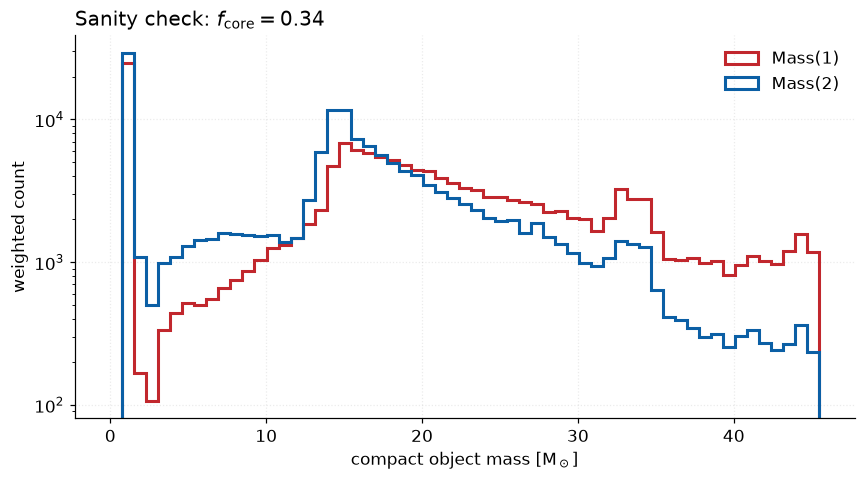

In [11]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linestyle": ":",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})

M1, M2 = "Mass(1)", "Mass(2)"        # <-- change to your column names
w = df[WEIGHT_COLUMN] if WEIGHT_COLUMN else None

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, np.nanpercentile(df[[M1, M2]].values, 99.9), 60)
ax.hist(df[M1], bins=bins, weights=w, histtype="step", lw=2, color="#C1272D", label=M1)
ax.hist(df[M2], bins=bins, weights=w, histtype="step", lw=2, color="#0B5FA5", label=M2)
ax.set_yscale("log")
ax.set_xlabel(r"compact object mass [M$_\odot$]")
ax.set_ylabel("weighted count" if WEIGHT_COLUMN else "number of systems")
ax.set_title(f"Sanity check: {submodels[fiducial]}", loc="left")
ax.legend()
plt.tight_layout()
plt.show()

## F.5 Cross-check the metadata table of Task E

Now that the file is open, go back to the **tier-1 rows of Task E** and check them against the
data. The cell below prints the range of whichever initial-condition columns your file has.

⚠️ **Read the result carefully.** This table is (usually) a *subset* of everything that was
simulated — only the binaries that became compact-object pairs. So:

- a value you see here **proves** the sampled range reaches at least that far;
- a value you *don't* see proves nothing at all.

So this check can **falsify** a number from the paper, but it cannot confirm one. If the data
disagrees with the paper, write it down in Task E as 🤔 and ask on Discord.

In [12]:
# columns that describe the initial conditions -- keep the ones your file has
CANDIDATES = ["Mass@ZAMS(1)", "Mass@ZAMS(2)", "Metallicity@ZAMS(1)", "Metallicity@ZAMS(2)",
              "SemiMajorAxis@ZAMS", "Eccentricity@ZAMS", "Time", "Coalescence_Time"]

present = [c for c in CANDIDATES if c in df.columns]
if present:
    check = pd.DataFrame({
        "min": [df[c].min() for c in present],
        "max": [df[c].max() for c in present],
        "n unique": [df[c].nunique() for c in present],
    }, index=present)
    check["grid or continuous?"] = np.where(check["n unique"] < 100, "looks like a GRID", "continuous")
    print(check.to_string())
else:
    print("None of the usual initial-condition columns are in this group -- "
          "check the other groups (e.g. BSE_System_Parameters), or the paper.")

# example of the falsification check described above:
if "Mass@ZAMS(1)" in df.columns:
    print(f"\nLowest initial primary mass present in this table: {df['Mass@ZAMS(1)'].min():.2f} Msun")
    print("  -> the sampled range must extend AT LEAST this low. Compare with the paper.")

                       min     max  n unique grid or continuous?
Mass@ZAMS(1)         5.062     150   2484379          continuous
Mass@ZAMS(2)         1.688   149.6   2484379          continuous
Metallicity@ZAMS(1) 0.0001 0.02999   2484379          continuous

Lowest initial primary mass present in this table: 5.06 Msun
  -> the sampled range must extend AT LEAST this low. Compare with the paper.


## F.6 What does your file contain that the tutorial file does not — and the other way round?

In onboarding Notebook 2 everybody worked with one specific file: the fiducial COMPAS simulation of
van Son et al. (2022a, 2023), `COMPAS_Output_wWeights.h5` from
[Zenodo 7612755](https://doi.org/10.5281/zenodo.7612755). Because we all know that file, it makes a
useful **reference point**: saying *"my file is like the tutorial file, but it has no
`BSE_System_Parameters` group and it adds the ZAMS masses to the DCO table"* tells another task
force member almost everything in one sentence.

⚠️ **Published simulation files are not standardised.** Authors save whichever columns their own
analysis needed, and nothing else. Two files from the *same code*, the *same group* and even the
*same first author* routinely differ. So this comparison is not busywork — it is how we find out
what we can and cannot do with your dataset.

### Three questions to answer explicitly

1. **Are there weights?** ⚖️ Look for a `mixture_weight` column (or `weight`, `sampling_weight`).
   **Not every dataset has them.** If yours does, the simulation used
   [adaptive importance sampling](https://en.wikipedia.org/wiki/Importance_sampling) and you must
   sum weights rather than count rows (onboarding Notebook 2, §1.4). If it does *not*, find out from
   the paper how the binaries were drawn — a fairly sampled file needs no weights, but a file that
   *should* have them and does not is a serious limitation. Note that a weight column is **not**
   part of standard COMPAS output: it is added afterwards by the sampling code, which is exactly
   why some files have it and others do not.
2. **Are the initial conditions there?** Especially the **initial separation** — the semi-major
   axis at birth (`SemiMajorAxis@ZAMS`, sometimes an orbital period instead). Many published files
   drop it, and without it you cannot study how the orbit shrank, reconstruct the formation
   channel, or check the initial separation distribution. Ask the same question for the initial
   masses (`Mass@ZAMS(1/2)`), the eccentricity and the metallicity.
3. **Which groups are missing?** If there is no group holding *all* simulated binaries
   (`BSE_System_Parameters` in COMPAS), you cannot compute **formation efficiencies** — how many
   double compact objects form per unit of stellar mass — from the file alone, because you do not
   know the total mass that was evolved. That is a big deal for the catalog, so flag it clearly.

The two cells below do the comparison automatically.

In [13]:
# The structure of the TUTORIAL 2 file, as a reference point
# (van Son et al. 2022a/2023 fiducial model, Zenodo 10.5281/zenodo.7612755)
TUTORIAL2 = {
    "BSE_System_Parameters": [
        "Mass@ZAMS(1)", "Mass@ZAMS(2)", "Metallicity@ZAMS(1)", "SEED",
        "Stellar_Type@ZAMS(1)", "Stellar_Type@ZAMS(2)"],
    "BSE_Double_Compact_Objects": [
        "CE_Event_Counter", "Coalescence_Time", "Immediate_RLOF>CE", "MT_Donor_Hist(1)",
        "MT_Donor_Hist(2)", "Mass(1)", "Mass(2)", "Merges_Hubble_Time", "Metallicity@ZAMS(1)",
        "Optimistic_CE", "SEED", "Stellar_Type(1)", "Stellar_Type(2)", "Time", "mixture_weight"],
    "BSE_RLOF": [
        "CEE>MT", "Eccentricity<MT", "Eccentricity>MT", "MT_Event_Counter", "Mass(1)<MT",
        "Mass(1)>MT", "Mass(2)<MT", "Mass(2)>MT", "RLOF(1)>MT", "RLOF(2)>MT", "SEED"],
    "Rates_*": ["DCOmask", "merger_rate", "merger_rate_z0", "redshifts"],
}


def normalise(group):
    """Rates group names encode the star formation history, so match them by prefix."""
    return "Rates_*" if group.startswith("Rates_") else group


with h5py.File(DATA_PATH, "r") as f:
    mine = {normalise(g): sorted(f[g].keys()) for g in f.keys() if hasattr(f[g], "keys")}

print("=" * 78)
print("GROUPS")
print("=" * 78)
for g in sorted(set(TUTORIAL2) | set(mine)):
    in_tut, in_mine = g in TUTORIAL2, g in mine
    mark = "both" if (in_tut and in_mine) else ("MISSING from mine" if in_tut else "EXTRA in mine")
    print(f"  {g:<34s} {mark}")

for g in sorted(set(TUTORIAL2) & set(mine)):
    missing = [c for c in TUTORIAL2[g] if c not in mine[g]]
    extra = [c for c in mine[g] if c not in TUTORIAL2[g]]
    print("\n" + "-" * 78)
    print(f"GROUP {g}")
    print(f"  columns MISSING compared to the tutorial file ({len(missing)}): "
          + (", ".join(missing) if missing else "none"))
    print(f"  columns the tutorial file does NOT have ({len(extra)}): "
          + (", ".join(extra) if extra else "none"))

GROUPS
  BSE_Double_Compact_Objects         both
  BSE_RLOF                           both
  BSE_System_Parameters              MISSING from mine
  Rates_*                            both

------------------------------------------------------------------------------
GROUP BSE_Double_Compact_Objects
  columns MISSING compared to the tutorial file (2): Coalescence_Time, Time
  columns the tutorial file does NOT have (4): Mass@ZAMS(1), Mass@ZAMS(2), Stellar_Type@ZAMS(1), Stellar_Type@ZAMS(2)

------------------------------------------------------------------------------
GROUP BSE_RLOF
  columns MISSING compared to the tutorial file (0): none
  columns the tutorial file does NOT have (0): none

------------------------------------------------------------------------------
GROUP Rates_*
  columns MISSING compared to the tutorial file (0): none
  columns the tutorial file does NOT have (0): none


In [14]:
# Does my file contain the things that matter most? Search EVERY group for the usual names.
PROBES = {
    "weights":              ["mixture_weight", "weight", "sampling_weight", "p_det"],
    "initial separation":   ["SemiMajorAxis@ZAMS", "SemiMajorAxis", "Separation@ZAMS",
                             "Orbital_Period@ZAMS", "Period@ZAMS"],
    "initial masses":       ["Mass@ZAMS(1)", "Mass@ZAMS(2)"],
    "initial eccentricity": ["Eccentricity@ZAMS"],
    "metallicity":          ["Metallicity@ZAMS(1)", "Metallicity@ZAMS(2)", "Metallicity"],
    "formation time":       ["Time"],
    "delay / merger time":  ["Coalescence_Time", "Delay_Time"],
    "final separation":     ["SemiMajorAxis@DCO", "SemiMajorAxis>CE"],
    "supernova / kicks":    ["Drawn_Kick_Magnitude(SN)", "Applied_Kick_Magnitude(SN)",
                             "SystemicSpeed", "Supernova_State"],
    "stellar types":        ["Stellar_Type(1)", "Stellar_Type(2)"],
    "binary ID (SEED)":     ["SEED"],
    "merges in hubble time?": ["Merges_Hubble_Time", "merge"]
}

with h5py.File(DATA_PATH, "r") as f:
    everything = {g: set(f[g].keys()) for g in f.keys() if hasattr(f[g], "keys")}

for what, names in PROBES.items():
    hits = [f"{n}  (in {g})" for g, cols in everything.items() for n in names if n in cols]
    status = "YES" if hits else "NOT FOUND"
    print(f"{status:>10s}  {what:<22s} " + (hits[0] if hits else "-- check the paper / other spellings"))
    for h in hits[1:]:
        print(f"{'':>10s}  {'':<22s} {h}")

       YES  weights                mixture_weight  (in BSE_Double_Compact_Objects)
 NOT FOUND  initial separation     -- check the paper / other spellings
       YES  initial masses         Mass@ZAMS(1)  (in BSE_Double_Compact_Objects)
                                   Mass@ZAMS(2)  (in BSE_Double_Compact_Objects)
 NOT FOUND  initial eccentricity   -- check the paper / other spellings
       YES  metallicity            Metallicity@ZAMS(1)  (in BSE_Double_Compact_Objects)
 NOT FOUND  formation time         -- check the paper / other spellings
 NOT FOUND  delay / merger time    -- check the paper / other spellings
 NOT FOUND  final separation       -- check the paper / other spellings
 NOT FOUND  supernova / kicks      -- check the paper / other spellings
       YES  stellar types          Stellar_Type(1)  (in BSE_Double_Compact_Objects)
                                   Stellar_Type(2)  (in BSE_Double_Compact_Objects)
       YES  binary ID (SEED)       SEED  (in BSE_Double_Compact_Obj

> 💡 **"NOT FOUND" does not always mean "not there".** Column names change between code versions
> and between codes. Check the printed column list of §F.2 by eye before concluding something is
> absent — and if you find a name we did not think of, tell us so we can add it to `PROBES`.

### 📖 What do all these column names actually mean?

The COMPAS documentation lists every property the code can write out:

| | |
|---|---|
| 📋 **Which columns each output file contains by default** | 👉 [Default record specifications](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-default-record-specifications.html) |
| 📖 **What each *stellar* property means, in words** — alphabetical, with a description and the header strings used in the file (`Age`, `Mass(1)`, `Stellar_Type(2)`, ...) | 👉 [Stellar properties](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-record-specification-stellar.html) |
| 📖 **What each *binary* property means, in words** — the same, for properties of the binary (`SemiMajorAxis`, `Eccentricity`, `Time`, ...) | 👉 [Binary properties](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-record-specification-binary.html) |
| 📚 All COMPAS documentation | 👉 [compas.readthedocs.io](https://compas.readthedocs.io/) |

Those two "properties" pages are the ones to use when you meet a column you do not recognise: each
entry gives a one-line description *in words* plus the **header string**, which is exactly the name
you see as a column in the HDF5 file.

> ⚠️ **Names change over time.** The documentation describes the *current* version of COMPAS; your
> file may have been written years earlier, so a column may be spelled differently or may no longer
> exist. Use the docs to understand the *meaning*, and the paper to settle anything ambiguous.
> If your data comes from a different code (COSMIC, SEVN, StarTrack, ComBinE, ...), find that
> code's equivalent documentation page and **put the link in your notebook** — we are collecting
> these.


## 📝 Fill in: my file compared with the tutorial file

👉 **Double-click to edit.**
*(van Son et al. 2022 "No peaks without valleys", $\zeta_\mathrm{eff}=4.5$ submodel)*

| | Tutorial 2 file | This file | Consequence |
|---|---|---|---|
| Groups | 4 |  **3** — no `BSE_System_Parameters` | Can't verify the total number of binaries simulated, will have to take the paper's word for the $10^7$ figure; **can't compute formation efficiencies** |
| Double compact objects | 2,523,122 | 2,484,379 | Comparable |
| ⚖️ Weight column | `mixture_weight` | ✅ `mixture_weight` | always sum weights, never count rows |
| Initial masses | ✅ `Mass@ZAMS(1/2)` (in `BSE_System_Parameters`) | ✅ `Mass@ZAMS(1/2)` in `BSE_Double_...` | Initial and final masses are avaialble in one group, but only for binaries that became DCO |
| **Initial separation (semi-major axis)** | ❌ not in the file | ❌ not in the file | Can't studdy orbital evolution |
| Initial eccentricity | ❌ not in the file | ❌ not in the file  | Can't study eccentrity evoluation |
| Initial stellar types | in `BSE_System_Parameters` | ✅ `Stellar_Type@ZAMS(1/2)` in the DCO table | Can identify the chemically homogeneous (type 16) systems |
| Metallicity | ✅ `Metallicity@ZAMS(1)` | ✅ `Metallicity@ZAMS(1)` | Can examine metallicity-dependent DCO properties and weighted distributions |
| Formation time / delay time | ✅ `Time`, `Coalescence_Time` | ❌ `Time`, `Coalescence_Time` | Can't compute delay time distributions |
| Supernova / kick information | ❌ not in the file | ❌ not in the file | Cannot directly examine natal kicks, supernova mass loss or orbital changes across individual supernovae. |
| `BSE_RLOF` | 31.9 M rows, 11 columns | 18.3 M rows, the same 11 columns | Not sure? |
| Pre-computed rates | ✅ | ✅ (same star formation history parameters) | Can use the supplied rates for their recorded assumptions |


**Columns my file has that the tutorial file does not:** The `BSE_System_Parameters` group. The `Time` and `Coalescence_Time` columns from the DCO table. \
**Columns the tutorial file has that mine is missing:** The columns `Mass@ZAMS(1)`, `Mass@ZAMS(2)`, `Stellar_Type@ZAMS(1)`, `Stellar_Type@ZAMS(2)` have been added to the DCO table. \
**What can I therefore NOT do with my dataset?** I cannot do the following from this file alone without going back to the authors,
- Verify the total number of binaries simulated.
- Compute formation efficiencies without external normalization.
- Recompute merger rates for a different star formation history.
- Calculate delay-time distributions.



<details>
<summary>👀 <b>Click here for a worked example</b></summary>

*(van Son et al. 2022 "No peaks without valleys", $\zeta_\mathrm{eff}=4.5$ submodel)*

| | Tutorial 2 file | This file | Consequence |
|---|---|---|---|
| Groups | 4 | **3** — no `BSE_System_Parameters` | cannot count the simulated binaries or compute formation efficiencies from the file; the $10^7$ comes from the paper |
| Double compact objects | 2,523,122 | 2,484,379 | comparable |
| ⚖️ Weight column | `mixture_weight` | ✅ `mixture_weight` | must sum weights, never count rows |
| Initial masses | in `BSE_System_Parameters` | ✅ **moved into** the DCO table (`Mass@ZAMS(1/2)`) | convenient — initial and final masses in one table, but only for the binaries that became a DCO |
| **Initial separation** | ❌ | ❌ | cannot study orbital shrinkage or the initial separation distribution |
| Initial stellar types | in `BSE_System_Parameters` | ✅ `Stellar_Type@ZAMS(1/2)` in the DCO table | lets me spot the chemically homogeneous (type 16) systems |
| Formation / delay times | ✅ `Time`, `Coalescence_Time` | ❌ **both missing** | cannot compute delay time distributions — a real limitation, and part of why the file ships pre-computed rates |
| `BSE_RLOF` | 31.9 M rows, 11 columns | 18.3 M rows, the same 11 columns | fewer rows; the columns match |
| Pre-computed rates | ✅ | ✅ (same star formation history parameters) | |

**Extra columns in this file:** `Mass@ZAMS(1)`, `Mass@ZAMS(2)`, `Stellar_Type@ZAMS(1)`,
`Stellar_Type@ZAMS(2)`, added to the DCO table.
**Missing:** the whole `BSE_System_Parameters` group, plus `Time` and `Coalescence_Time` from the
DCO table.
**So I cannot:** compute formation efficiencies, or delay time distributions, without going back to
the authors or re-running the simulation.

</details>

---

---

<a id="taskG"></a>
# Task G — The dataset summary card

This is the **deliverable** of step 1: the information that goes into the GROWL catalog, and what
you will present at the next meeting.



👉 **Double-click to edit.** One card **per submodel** (copy the table if you have several).

| Field | Value |
|---|---|
| **Dataset name** (`name_folder` from Task B) | van Son et al. 2022 "No peaks without valleys" Dataset 1; `vanSon22NoPeaks_1` |
| **Submodel** (folder name) | `faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED` |
| **Is this the fiducial model?** | No |
| **Paper** (journal ref + DOI + arXiv) | ApJ 940, 184 — https://doi.org/10.3847/1538-4357/ac9b0a — arXiv:2209.13609  |
| **Data DOI / archive** | `10.5281/zenodo.7080725` (part 1 of 2) |
| **Authors' analysis code** | https://github.com/LiekeVanSon/LowMBH_and_StableChannel |
| **Simulation code + version** | COMPAS v02.26.03 |
| **File name and format** | `COMPAS_Output_weights.h5` |
| **File size** | 3.69 GB |
| **Path on the GROWL drive** | `\vanSon22NoPeaks_1\faccFIXEDbeta0_5zetaHG4_5RemMassFRYER2012SNDELAYED\COMPAS_Output_weights.h5` |
| **Number of binaries simulated** (and *where that number comes from*) | $10^7$ (paper) |
| **Number of double compact objects** | 2,484,379 |
| **Number that merge within a Hubble time** | 1,401,406 |
| **Groups in the file** | 3 — `BSE_Double_Com...`, `BSE_RLOF`, and `Rates...`|
| **Weight column** (name, or "none") | `mixture_weight` |
| **Sum of weights** | ~152200 |
| **Sampling strategy** (fair / importance sampled / grid) | Adaptive importance sampling (STROOPWAFEL) |
| **Metallicities** (range; continuous or a discrete grid; how many values) | Continuous, flat-in-log sampling over $10^{-4}\leq Z\leq0.03$; 2,484,379 (201) (total or distinct?) |
| **Initial mass function, mass ratio, separation distributions** | Kroupa (2001), , |
| **Units** (mass, time, separation) | $M_\odot , \, Myr$, N/A |
| **Physics that differs from the paper's fiducial model** | $\zeta_{\mathrm{eff}}=4.5$, transfer becomes unstable more quickly (fiducial = 6.0) |
| **Does it include pre-computed merger rates?** (which star formation history?) | Yes (Neijssel et al. (2019).) |
| **Known quirks / missing pieces** | Total number and mass of simulated binaries, formation and delay time, initial separation and eccentrcity are unavailable. <br> `Optimistic_CE` and `Immediate_RLOF>CE` all zero; RLOF table has no weights |
| **Open questions for the group** | (?) |

## ✅ Step 1 checklist

Tick these off before the meeting:

**Task A**
- ✅ I have read the paper and can say what it is about in two sentences.
- ✅ I have found the data archive and recorded its **DOI**.
- ✅ I have checked that the archive cites the **right** paper.
- ✅ I have listed **all** the submodels and decoded their names.
- ✅ I know which submodel is the **fiducial** one.

**Task B**
- ☐ I have chosen `name_folder` (and checked whether it already exists on the GROWL drive).
- ✅ My submodel folder names are **as close as possible to the download names**.
- ✅ My path dictionary runs and finds every file.

**Task C**
- ✅ I have downloaded my file(s) and **verified the checksum**.
- ✅ My download recipe is written down step by step, with the real commands.
- ✅ I have written down the difficulties I hit.
- ✅ A copy of the paper and of the archive README sits next to the data.

**Task D**
- ✅ I have summarised the paper's goal and findings **in my own words**.
- ✅ I have **verified every sentence I wrote** against the paper itself.
- ✅ I know which **DCO types** the paper studies.
- ✅ I have listed **every figure** and the properties plotted in it *(last column left)*.
- ✅ I have asked in Discord about everything I was not sure of.

**Task E**
- ✅ I have read the **methods section** of the paper.
- ✅ The **tier-1** rows of the metadata table are filled in: code + version, number of binaries,
  ZAMS mass range + IMF, mass ratio distribution, metallicities.
- ✅ **Every** entry has a source (section / table / equation number), or says "not stated".
- ✅ Where the paper defers to an earlier paper, I recorded **which** paper the value came from.
- ✅ I have flagged everything I could not verify, instead of guessing.

**Task F**
- ✅ I have listed **every group and every column**.
- ✅ I know whether there is a **weight column**, and what it means if there is not.
- ✅ I know what the **units** are.
- ✅ I have made one sanity plot and it looks physical.
- ✅ I know whether my file has **initial separations** (and the other initial conditions).
- ✅ I have compared my file with the **tutorial file** and written down what is added and missing.
- ✅ I have written down what I therefore **cannot** do with this dataset.

**Task G**
- ✅ The summary card is filled in.
- ✅ I went back to the metadata table of Task E and cross-checked it against the data.
- ✅ I have written down at least one thing that **confused me** or is **missing** from the data.

> 🎉 **That last point is not a formality.** Every dataset in the catalog has quirks, and the person
> who finds them is doing the rest of the task force a real favour. Come to the meeting with your
> questions.

---

## 📎 Appendix — Useful references

- **Onboarding notebooks** — [1: population synthesis](../../../onboarding_growl/tutorial_1_introduction_to_population_synthesis.ipynb) ·
  [2: a population of GW sources](../../../onboarding_growl/tutorial_2_analysing_a_population_of_gravitational_wave_sources.ipynb) ·
  [3: cosmic integration](../../../onboarding_growl/tutorial_3_cosmic_integration_predicting_merger_rates.ipynb)
- **A worked example on a real dataset** — the van Son+22 "No peaks without valleys" project folder:
  **this folder** (`vanSon22noPeaks_1__Maryam_Ahsan/`) — the notebook next to this one
- **Reviews** — Mandel & Broekgaarden (2022), *Rates of compact object coalescences*,
  [arXiv:2107.14239](https://arxiv.org/abs/2107.14239) · Breivik et al. (2025), population synthesis
  review, [arXiv:2502.03523](https://arxiv.org/abs/2502.03523)
- **COMPAS** — [compas.science](https://compas.science/) ·
  [methods paper](https://arxiv.org/abs/2109.10352) ·
  [all documentation](https://compas.readthedocs.io/)
- **📖 What every COMPAS column means, in words** — the two pages to keep open whenever you meet a
  column you do not recognise. Each entry gives a description *and* the **header string**, which is
  the literal column name in the HDF5 file:
  [**Stellar properties**](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-record-specification-stellar.html)
  (properties of a star: `Age`, `Mass(1)`, `Stellar_Type(2)`, ...) ·
  [**Binary properties**](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-record-specification-binary.html)
  (properties of the binary: `SemiMajorAxis`, `Eccentricity`, `Time`, ...) ·
  [which columns each logfile gets by default](https://compas.readthedocs.io/en/latest/pages/User%20guide/COMPAS%20output/standard-logfiles-default-record-specifications.html)
- **h5py** — [docs](https://docs.h5py.org/) · **pandas** — [docs](https://pandas.pydata.org/docs/)
- **HDF5 from the command line** (no Python needed, very handy):
  ```bash
  h5ls -r file.h5          # list every group and dataset
  h5dump -H file.h5        # print the full header, including attributes
  ```
